# Task 3: predicting next-day volatility-adjusted returns of S&P 500 stocks

This section is self-contained. It reads only the six CSV files in `data/` and contains all the code of our Task 3 study, copied from our repository's `src/` folder, with its outputs.

What it does, top to bottom:

1. The protocol we gave to the coding agent (Claude Code), and a summary of its record of questions, decisions and problems.
2. Data loading, cleaning and exploration.
3. Volatility adjustment (Figure 1).
4. The evaluation code and the three harness controls.
5. Features and the guard that forbids training on future rows.
6. Models and the walk-forward engine.
7. All 62 development configurations tried before the freeze, re-run here with the same settings.
8. The frozen finalists.
9. The single test evaluation on 2011-2013, then two post-hoc analyses (Figure 2).
10. The total number of configurations.

Every recomputed number that appears in our experiment log is compared, to 4 decimals, with the value we recorded at the time; those recorded values are written into the `VERIFY` dict near the top. Running the whole section takes about two and a half hours on an 8-core laptop, almost all of it in Section 7 and Section 9.

## 1. Protocol and agent record

### 1.1 The agent prompt (`AGENT_PROMPT.md`, full text)

The prompt is quoted below exactly as given to the agent.

> # Task 3 Agent Prompt (ECSE 551, Assignment 1)
>
> You are working in our group's repository for ECSE 551 Assignment 1, Task 3: predicting next-day volatility-adjusted returns of S&P 500 stocks from historical returns and sentiment signals.
>
> Your job is to run a careful, honest experimental study under a fixed protocol. You are NOT optimizing for the highest possible number. A negative result is acceptable and must be reported honestly. Every member of our group will be questioned individually in an oral demo about every line of code and every result, so clarity and correctness matter more than cleverness.
>
> Before doing anything else, read this entire file, then reply with a short plan and any questions. Do not start Phase 0 until we answer.
>
> ---
>
> ## 0. Ground rules (apply throughout, no exceptions)
>
> 1. **Frozen harness.** After Phase 0, `src/task3_data.py` and `src/task3_eval.py` are frozen. You may import them but never edit them. At every checkpoint, run `git diff $(cat results/FROZEN_COMMIT.txt) -- src/task3_data.py src/task3_eval.py` and show us the output. It must be empty. If you believe the harness has a bug, stop and tell us; do not fix it yourself.
>
> 2. **Test set lockout.** The test period is 2011-01-01 to 2013-12-31. During Phases 1 and 2 you must never compute any metric, plot, or statistic on test-period predictions or test-period returns. All model selection and hyperparameter tuning uses the development period only. The test period is evaluated exactly once, in Phase 3, only for finalists we approve, and only after the frozen configurations have been committed.
>
> 3. **No lookahead.** A prediction made at the close of day t may use only information available at the close of day t. Concretely:
>    - Features at row t may only use data from rows up to and including t.
>    - The training target for row s is the clipped vol-adjusted return on day s+1. That return is only known at the close of s+1. Therefore a model used to predict on day t may only be trained on rows s <= t-1. Enforce this with an `assert` in the training code, not just a comment.
>    - Sentiment follows the timing rule in Section 2.5.
>    - Leakage tests in Phases 1 and 2 are mandatory.
>
> 4. **Experiment log.** Every configuration you evaluate (including failed runs, controls, and anything you abandon) gets one row appended to `results/experiment_log.csv`. Never delete or edit rows. Columns: `exp_id, timestamp, phase, model, features, hyperparams, target_variant, demean, pred_smoothing_halflife, refit_every, train_window, dev_sharpe, dev_sharpe_1990_1999, dev_sharpe_2000_2010, mean_ic, ic_tstat, holding_period, corr_market, min_preds_per_day, runtime_s, notes`. We will report the total number of configurations tried, because that is the multiple-testing context for any result.
>
> 5. **Scope.** Only the model families the assignment asks for: sparse linear regression (Lasso), a basic MLP, and a random forest, plus the simple rule-based baselines listed below. scikit-learn implementations are allowed for Task 3. No gradient boosting libraries, no deep learning frameworks, no external data.
>
> 6. **Code we can explain.** Plain functions with short docstrings that say what the function does and why. Comments on every line that involves a time shift (`shift`, `rolling`, `ewm`, date slicing), stating which days the value depends on. No class hierarchies, decorators, or clever pandas one-liners where a clear three-line version exists. Keep each module under about 300 lines. Fixed random seed 42 everywhere. The final submission is a single notebook, so modules must be self-contained enough to paste into notebook cells.
>
> 7. **Checkpoints.** At the end of each phase, stop: summarize what you did in plain language, show results, list any decisions you made and why, show the frozen-harness diff, then end your turn and wait for us to reply "continue". Do not start the next phase on your own.
>
> 8. **Git hygiene.** Commit locally at the end of each phase with message `task3 phase N: <summary>`. Never commit anything in `data/`. Never push, force, rebase, or rewrite history.
>
> 9. **Boundaries.** Do not modify files for Tasks 1 and 2, the `report/` folder, or `notebooks/task3.ipynb`. Use the current Python environment; ask before installing any package.
>
> 10. **When in doubt, stop and ask.** If a rule blocks something you think is necessary, explain the problem instead of working around it.
>
> 11. **Running record.** Maintain `results/AGENT_LOG.md` throughout: each decision with its reason, each problem with its fix, and each question you asked us with our answer. This file is cited in our report.
>
> ---
>
> ## 1. Repository layout
>
> ```
> data/                    CSVs (gitignored, read-only for you)
> notebooks/task3.ipynb    our verified exploration, source of truth for Section 2 (do not edit)
> src/                     modules (you create task3_*.py here)
> tests/                   tests (you create)
> results/                 logs, tables, figures (you create)
> AGENT_PROMPT.md          this file
> ```
>
> ---
>
> ## 2. Established pipeline (built and verified by us)
>
> `notebooks/task3.ipynb` contains our verified implementation of everything in this section. When extracting it in Phase 0, copy the logic exactly.
>
> ### 2.1 Data facts
>
> - `eq_returns.csv`: rows are trading days (8577 days, 1980-01-02 to 2013-12-31), columns are permnos plus a `date` column. Values are daily excess returns as decimals.
> - `eq_indicator.csv`: same shape. 1 if the stock is an S&P 500 member that day, else 0. About 500 members per day (min 489).
> - `eq_stock_metadata.csv`: `permno, cname, gics` (8-digit GICS; sector = first 2 digits).
> - `psych_bullish.csv`, `psych_bearish.csv`: rows are CALENDAR days (weekends included) starting 2009-07-10. Columns are permnos (606 stocks). NaN most likely means no messages that day, which is different from a score of 0.
> - `psych_stock_metadata.csv`: `permno, ticker` (not needed for joining).
>
> ### 2.2 Cleaning (already decided, reproduce exactly)
>
> - 21 permnos appear twice as column headers. pandas renames the second copy `XXXX.1`. We rename it `XXXX_b` and treat it as a distinct security, because the two series are never identical (correlation 0.06 to 0.47 on overlapping days) and are often both members on the same day. The metadata has matching duplicate rows in the same order; the second occurrence gets id `XXXX_b`.
> - 21 columns with no data at all are dropped, leaving 1314 securities.
> - Stock ids stay strings throughout (`"12431_b"` is not an integer).
> - Non-member days have returns for about 255 stocks per day (2,190,592 cells). These are used ONLY for volatility estimation and feature construction, never as training targets, predictions, or evaluation. The dataset only contains stocks that were members at some point in 1980 to 2013, so training on pre-inclusion days would leak future index membership.
>
> ### 2.3 Volatility adjustment
>
> Per stock, every day, in this order (EWMA filters, assignment eqs. (2) and (3)):
>
> ```
> mu_t     = (1 - beta2) * r_t + beta2 * mu_{t-1}
> a_t      = r_t - mu_t
> sigma2_t = (1 - beta1) * a_t^2 + beta1 * sigma2_{t-1}
> vadj_t   = r_t / sigma_{t-1}          # note t-1: implemented as sig.shift(1)
> ```
>
> beta1 = 0.97, beta2 = 0.99, initial variance 0.02**2, burn-in of 100 observations per stock (sigma is NaN before that), state carried forward unchanged on NaN days.
>
> ### 2.4 Targets, masks, and evaluation
>
> - `vadj_c = vadj.clip(-5, 5)`: for features and training targets only.
> - `Y = vadj.shift(-1)`: UNclipped, for evaluation only. `Y[t]` is the realized vol-adjusted return on day t+1, earned by a prediction made at the close of day t.
> - `mem = ind.astype(bool)`.
> - `evaluate(P, start, end, windows, demean, label, plot)`: takes a prediction DataFrame `P` (dates x stocks, `P[t]` = prediction made at close of day t), restricts to members on day t, optionally demeans each day, and reports: annualized Sharpe of the daily P&L `sum_i P[t,i] * Y[t,i]`, Sharpe by year and by window, mean daily Spearman rank IC and its t-stat, cumulative P&L and cumulative IC plots, average holding period (assignment eq. (7), stocks with at least 20 predictions), correlation of the P&L with an equal-weight long-only portfolio of members, and the minimum number of predictions per day.
>
> ### 2.5 Sentiment timing rule
>
> Sentiment for calendar day d may contain posts made after that day's market close. To be safe, sentiment dated d is first usable for the prediction made at the close of the first trading day STRICTLY AFTER d. Sentiment from non-trading days (weekends, holidays) is aggregated into that same first usable trading day. Example: Friday, Saturday, and Sunday sentiment all become usable at Monday's close; Monday's sentiment becomes usable at Tuesday's close.
>
> Of the 19 duplicated permnos that remain, check which have sentiment columns. For each one, if exactly one of the two securities has returns during the sentiment period, map the sentiment to that one. If both do, exclude sentiment for both. Log what you did in `AGENT_LOG.md`.
>
> ---
>
> ## Phase 0: Extract, verify, freeze (then STOP)
>
> 1. Create `src/task3_data.py` with `load_data()`, `ewma_vol()`, and `build_targets()` (returning `ret, ind, meta, sig, vadj, vadj_c, Y, mem`), copying the logic from the notebook. The only allowed change is turning globals into function arguments or return values.
> 2. Create `src/task3_eval.py` with `sharpe()` and `evaluate()`, copied from the notebook. Same allowed change only: `Y` and `mem` become arguments.
> 3. Create `tests/test_task3_pipeline.py` that checks these values reproduce (tolerance 1e-3 relative unless exact):
>
>    | Check | Expected |
>    |---|---|
>    | duplicated permno columns renamed `_b` | 21 |
>    | empty columns dropped | 21 |
>    | securities remaining | 1314 |
>    | metadata index equals return columns | True |
>    | mean members per day / min | 499.79 / 489 |
>    | member cells with NaN return | 0 |
>    | non-member cells with a return | 2,190,592 |
>    | non-NaN vol-adjusted returns on member cells | 4,227,347 |
>    | std of those | 1.0574 |
>    | excess kurtosis | 22.75 (tolerance 0.05) |
>    | fraction with abs value > 5 | 0.00076 |
>
> 4. Run the harness controls on 2011-01-01 to 2013-12-31 (this is the one allowed use of the test period before Phase 3, because these controls contain no model): perfect-foresight `P = Y` must give an absurd Sharpe (above 50); i.i.d. N(0,1) predictions with seed 42 must give an absolute Sharpe below 1.5; always-long `P = 1` must give market correlation above 0.9. Report the 5-day reversal baseline (`-vadj_c.rolling(5, min_periods=3).mean()`, demeaned) over 1985 to 2010 only.
> 5. Commit, write the commit hash to `results/FROZEN_COMMIT.txt`, commit that file too, and STOP with an expected-vs-actual table.
>
> ---
>
> ## Phase 1: Features and leakage tests (then STOP)
>
> Create `src/task3_features.py`. All features are computed per stock from data up to and including row t, then transformed cross-sectionally each day among members: rank, scaled to [-0.5, 0.5]. Missing values after ranking become 0 (neutral); log the fraction filled per feature.
>
> Return-based features (from `vadj_c` and `sig`):
> - `rev_1`: vadj_c on day t
> - `rev_5`: mean of vadj_c over days t-4..t
> - `rev_21`: mean over t-20..t
> - `mom_12_1`: sum over t-251..t-21 (skips the most recent month)
> - `vol_level`: log(sig_t)
> - sector-relative versions of `rev_5`, `rev_21`, `mom_12_1`: subtract the same-day mean among members of the same GICS sector (first 2 digits), before ranking
> - smoothed versions: EWMA over time of the ranked feature with half-lives 5 and 10 days
>
> Sentiment features (from 2009-07 onward, Section 2.5 timing): bullish, bearish, net = bullish - bearish, activity = bullish + bearish, each also EWMA-smoothed with half-lives 5 and 21 days, plus a 0/1 availability flag.
>
> Leakage tests in `tests/test_leakage.py` (mandatory):
> - **Truncation test:** for 20 random dates t (seed 42) spread across 1985 to 2010, recompute all features using only data up to t (returns, and sentiment respecting the timing rule) and assert row t matches the full-data computation to 1e-10.
> - **Training-window assertion:** a unit test showing the training function raises an error if given any row s >= t when predicting on day t.
>
> STOP with a feature table: name, formula, lookback in days, first available date, mean coverage among members.
>
> ---
>
> ## Phase 2: Walk-forward experiments on the development period (then STOP)
>
> ### Protocol
>
> - **Training data:** member rows only. Target = `vadj_c.shift(-1)`, cross-sectionally demeaned each day (default), or raw (one variant only).
> - **Walk-forward:** at each refit date d, fit on rows s in [d - window, d - 1], then predict every day from d until the next refit. Refit every 63 trading days for Lasso and every 252 trading days for random forest and MLP (compute budget). Training windows: 3 years, 5 years, expanding (try on Lasso; pick one for RF/MLP and log why).
> - **Development period:** predictions from 1990-01-01 to 2010-12-31. Selection metric: dev Sharpe of demeaned predictions, but prefer configurations that are consistent across the windows 1990-1994, 1995-1999, 2000-2004, 2005-2010 over ones with a higher total driven by one window. Report holding period for everything.
> - **Sentiment models:** sentiment starts 2009-07, so their development window is 2010-01-01 to 2010-12-31 with expanding training from 2009-07. That is very little data: use a tiny grid (at most 6 configurations) and flag the limitation clearly.
> - **Coverage:** at least 100 predictions per day; report the minimum.
>
> ### Models
>
> - Baselines: 5-day reversal, 12-1 momentum (rule-based, no fitting).
> - Lasso (`sklearn.linear_model.Lasso`): alpha grid of about 6 values on a log scale. Record which coefficients are nonzero at each refit.
> - Random forest (`RandomForestRegressor`): `n_estimators=100`, `max_depth` in {4, 6, 8}, `min_samples_leaf` in {200, 1000}, subsample 200,000 training rows per fit (seed 42), `n_jobs=-1`.
> - MLP (`MLPRegressor`): one hidden layer of 16 or 32 units, alpha in {1e-4, 1e-2}. Do NOT use `early_stopping=True`: it splits randomly, which mixes future and past. Instead, choose the number of epochs with a time-ordered holdout (the most recent 20% of each training window by date).
> - Post-processing variants on the best configurations: demean on/off, and EWMA smoothing of predictions over time with half-life in {0, 2, 5, 10} days to show the Sharpe vs holding-period trade-off.
>
> ### Budget and controls
>
> - At most about 60 configurations in total for Phase 2. Every one goes in the log.
> - **Positive control:** take one Lasso configuration and shift its features one day into the future (`shift(-1)`). The dev Sharpe must jump dramatically. This proves the pipeline is sensitive to leakage.
> - **Negative control:** same configuration, but permute training targets across stocks within each day. Dev Sharpe should be near 0.
> - Controls are logged but never eligible for selection.
> - If any single configuration takes more than about 15 minutes, reduce cost (fewer refits, smaller subsample), log it, and continue.
>
> STOP with: the full results table sorted by dev Sharpe, windowed Sharpe for the top configurations, the control results, and a proposal of at most 4 finalists (at least one Lasso, one random forest, one MLP, and a sentiment variant only if it looks viable), each with a short justification. Save figures to `results/figures/` as PDF with large fonts (at least 14 pt).
>
> ---
>
> ## Phase 3: Freeze, then test once (only after we approve the finalists)
>
> 1. Write the approved finalists to `results/final_configs.json` and commit with message `task3: freeze finalists` BEFORE running anything on the test period.
> 2. Run walk-forward predictions through 2013-12-31 with the same rules (training on rows up to t-1, same refit schedule) and evaluate each finalist plus the two baselines on 2011-01-01 to 2013-12-31, exactly once. Save to `results/test_results.csv`.
> 3. Do not change any configuration after seeing test results. If you discover a bug, stop and tell us; any fix and re-run must be disclosed in `AGENT_LOG.md` and the experiment log.
> 4. Also produce full walk-forward curves for 1990 to 2013, clearly marking 1990 to 2010 as the development period (used for selection, so not truly out-of-sample).
> 5. Figures (PDF, large fonts): cumulative P&L on the test period for all finalists and baselines; cumulative rank IC on the test period; Sharpe by window as a bar chart; Sharpe vs holding period scatter over all dev configurations plus finalists; Lasso nonzero-coefficient frequency across refits; random forest feature importances.
>
> ---
>
> ## Phase 4: Write-up support (then STOP)
>
> 1. `results/SUMMARY.md`: protocol, every number we need for the report, and an honest interpretation. Compare against the assignment's rough benchmarks: Sharpe of 0.6 or more is interesting for long holding periods, about 2 for one-day holding periods; standard error of the Sharpe is roughly 1/sqrt(years), so about 0.58 for the 3-year test period. State limitations plainly.
> 2. `results/EXPLAIN.md`: a walkthrough of every function in `src/task3_*.py`, in plain language, followed by about 15 likely demo questions with concise answers (e.g. why sigma_{t-1}, why train only on rows up to t-1, why demean, why rank features, what the controls show).
> 3. `notebooks/task3_agent.ipynb`: imports the modules and reproduces every final table and figure top to bottom, with outputs saved.
> 4. Final checks: frozen-harness diff empty, total configuration count from the log, all tests passing. Commit and STOP.

### 1.2 Summary of the agent's log (`results/AGENT_LOG.md`)

**Questions the agent asked before starting, and our answers**

| # | Question | Our answer |
|---|---|---|
| 1 | The prompt asked for a perfect-foresight Sharpe above 50, but our evaluation code gives 16.6 on 2011-2013. Lower the threshold? | Yes, to 10. The evaluation code was not changed. |
| 2 | The active Python environment has no scikit-learn. Reuse the environment of another project? | No. Stay in our environment and install numpy, pandas, scipy, scikit-learn, matplotlib, pytest, nbformat and ipykernel. |
| 3 | The repository has `notebook/`, the prompt assumes `notebooks/`. | Rename to `notebooks/`. |
| 4 | The repository has no commits yet. What goes into the first commit? | The agent never stages or commits. At each checkpoint it lists files and a message; a group member commits and sends back the hash. |

**Instructions we gave later**

| When | Instruction |
|---|---|
| After Phase 1 | Drop the six smoothed momentum and volatility features (correlation 0.97 to 0.99 with their base); decide the sentiment mapping for duplicated permnos with data up to 2010 only, and freeze it. |
| After Phase 2 | Run a grid extension of at most 5 configurations, replacing a finalist only if an extension beats it by more than 0.22 (one standard error of a 21-year Sharpe); run a delayed-execution diagnostic; write expected test ranges before the freeze. |
| Before the freeze | Make the slow finalist the MLP finalist's predictions smoothed with a half-life of 5 days, whatever its development Sharpe. |
| After the test | Post-hoc delayed execution and market hedge on the test period; audit the test suite after one unexplained failure. |

**Key decisions**

| Area | Decision |
|---|---|
| Harness | Data loading and evaluation copied unchanged from our exploration notebook and frozen (commit `cceeb15`); an empty diff against it was checked at every checkpoint. |
| Features | 18 return features, ranked across members each day to [-0.5, 0.5]; a missing rank becomes 0; smoothing is applied after filling. 13 sentiment features from 2009-07. |
| Training | A model predicting on day t trains only on rows dated before t (enforced by an `assert`); features standardized with training-window statistics; 3-year window; Lasso refit every 63 days, forest and MLP every 252. |
| Models | Lasso penalty grid derived from the first training window only; random forest with `max_features = 1/3` and 200,000 rows per fit; MLP epochs chosen on the most recent 20% of training days (no random early stopping). |
| Selection | Development Sharpe of demeaned predictions on 1990-2010, preferring consistency across four windows. Finalists committed (commit `f817d04`) before any test-period run. |
| Test | Evaluated once; the evaluation code refused to run a second time. |

**Problems and how they were resolved**

| # | Problem | Resolution |
|---|---|---|
| 1 | Perfect foresight gives 16.6, below the prompt's threshold of 50. | Threshold lowered to 10 (question 1). |
| 2 | Our exploration notebook reported 0.076% of vol-adjusted returns above 5, dividing by all date-stock cells. | Among actual member values the share is 0.201%; corrected in the report. |
| 3 | The first sentiment mapping rule looked at which duplicated securities have returns up to 2013. | Rule changed to use data up to 2010 only, and frozen. |
| 4 | Six smoothed features were near-copies of their base feature. | Dropped (18 return features remain). |
| 5 | Sentiment covers only about 12% of members per day. | Used only as an addition to return features; no sentiment finalist. |
| 6 | The best configuration of every family sat at the edge of its grid. | Grid extension with a replacement rule fixed in advance; the forest and the MLP finalists were replaced. |
| 7 | One leakage test failed once and could not be reproduced. | No shared or mutable state found; 7 later full runs passed. Not explained. |
| 8 | A notebook was edited while the agent was executing it. | Reported; the edits were kept. |

**The three disclosed contacts with the test period before the freeze**

1. *Boundary day.* Periods are defined by prediction date, so the last development prediction (2010-12-31) is scored by the frozen evaluation code against the return of 2011-01-03, the first trading day of the test year. No training row used a return after 2010-12-29.
2. *Sentiment availability.* While exploring the duplicated permnos, the agent printed how many non-missing returns and member days each security had in 2011-2013. No return value was viewed. The mapping rule was then changed to use data up to 2010 only (problem 3).
3. *Expected ranges not blind for the reversal baseline.* Our exploration notebook, read by the agent in Phase 0, showed the 5-day reversal Sharpe for 2011, 2012 and 2013. The agent's pre-freeze expectation for that baseline therefore was not blind.

Separately, the prompt itself required the three no-model harness controls on 2011-2013 and the distribution checks on the full 1980-2013 sample (Sections 3 and 4).

### 1.3 How the code below relates to our repository

The code cells marked `# Copied from src/...` contain whole functions copied from our modules. The only changes are:

1. Imports between our own modules are removed, since every function is defined in an earlier cell. `matplotlib.use("Agg")` lines, `STAGES` dicts and `if __name__ == "__main__"` blocks are removed, because they only serve command-line use.
2. Writes to files that this notebook does not need are removed. Results the notebook reuses are kept in memory instead:
   - `append_log` stores rows in the list `EXPERIMENT_LOG`, with the same columns and numbering, instead of `results/experiment_log.csv`.
   - `score_and_log` keeps window Sharpes in `DEV_WINDOWS_ROWS` and daily P&L in `DEV_PNL`. It keeps prediction tables in the dict `CACHE` only for the six experiments reused later (E005, E012, E029, E033, E058, E059); our scripts wrote all of them to disk. `load_cached` reads `CACHE`. `run_group` no longer calls `save_records`.
   - The Lasso penalty grid is kept in `LASSO_ALPHA_GRID` instead of a JSON file. `stage_post`, `stage_slow`, `stage_test` and the post-hoc stages read `EXPERIMENT_LOG` and the in-memory tables instead of CSV and pickle files. The phase 3 and post-hoc stages lose their "already run" file guards and return their tables.
   - `load_config` returns the inline `FINAL_CONFIGS` dict (Section 8), which is identical to our committed `results/final_configs.json`.
3. One historical value: `FINALISTS` in the phase 2 code is set as it was when the delayed-execution diagnostic (E061 to E065) was run, with the slow finalist still `"E033+hl5"`. Our source file was updated to `"E059+hl5"` afterwards, when the group changed the slow finalist; using that value would not reproduce E064.
4. The phase 2 diagnostic and the post-hoc analysis both define a function called `stage_delay`. The post-hoc version (Section 9) replaces the earlier one once Section 7 has run.

Frozen configurations, feature definitions and the evaluation code are unchanged.

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

%matplotlib inline
pd.set_option("display.width", 220, "display.max_rows", 120, "display.max_columns", 30)

ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir():            # walk up until the folder that contains data/
    if ROOT == ROOT.parent:
        raise FileNotFoundError("no folder containing data/ above the working directory")
    ROOT = ROOT.parent
os.chdir(ROOT)                                  # the code reads "data/..." and writes "results/figures/..."
FIGURES = Path("results/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
NOTEBOOK_START = time.time()
print("repository root:", ROOT)

repository root: /Users/louissalanon/ecse551-assignment1


In [2]:
# Values recorded in our experiment log at the time each run was made. Every recomputed number
# below is compared with them to 4 decimals. None means "not defined" (for example a window
# the sentiment study does not cover).
VERIFY = {'pipeline': {'securities': 1314,
              'duplicated_renamed': 21,
              'empty_dropped': 21,
              'mean_members': 499.793750728693,
              'min_members': 489,
              'member_nan_returns': 0,
              'nonmember_with_return': 2190592,
              'member_vadj_count': 4227347},
 'phase0': {'E001_sharpe': 16.59804803018954,
            'E002_sharpe': 0.3144750385636209,
            'E003_corr_market': 0.999998297642472,
            'E004_sharpe': 2.326809908805963},
 'dev': {'E005': {'name': 'baseline_rev_5',
                  'dev_sharpe': 2.1757299765873666,
                  'holding_period': 1.5621845991568175,
                  'sharpe_1990_1994': 4.08693769435408,
                  'sharpe_1995_1999': 2.591199274036234,
                  'sharpe_2000_2004': 1.394910746613251,
                  'sharpe_2005_2010': 1.2531352259139603},
         'E006': {'name': 'baseline_mom_12_1',
                  'dev_sharpe': 0.5196106315996423,
                  'holding_period': 10.907478989825472,
                  'sharpe_1990_1994': 0.850497216375393,
                  'sharpe_1995_1999': 1.2226901008628837,
                  'sharpe_2000_2004': -0.0124196175336374,
                  'sharpe_2005_2010': 0.2343221320288065},
         'E007': {'name': 'lasso_3y_a0',
                  'dev_sharpe': 2.4710838436705154,
                  'holding_period': 2.9852011,
                  'sharpe_1990_1994': 3.3634867749152972,
                  'sharpe_1995_1999': 3.486979324196389,
                  'sharpe_2000_2004': 2.1562095619644057,
                  'sharpe_2005_2010': 0.4034131629982053},
         'E008': {'name': 'lasso_3y_a1',
                  'dev_sharpe': 3.299183557110929,
                  'holding_period': 1.4879534,
                  'sharpe_1990_1994': 6.0295355041510685,
                  'sharpe_1995_1999': 3.7648749547675178,
                  'sharpe_2000_2004': 2.097544679319267,
                  'sharpe_2005_2010': 1.121500607109091},
         'E009': {'name': 'lasso_3y_a2',
                  'dev_sharpe': 3.583831145149083,
                  'holding_period': 1.3985504,
                  'sharpe_1990_1994': 6.753495256524532,
                  'sharpe_1995_1999': 4.0974423762422,
                  'sharpe_2000_2004': 2.1377761646678413,
                  'sharpe_2005_2010': 1.363013829233257},
         'E010': {'name': 'lasso_3y_a3',
                  'dev_sharpe': 3.8588772386794545,
                  'holding_period': 1.3949175,
                  'sharpe_1990_1994': 7.1085140676473335,
                  'sharpe_1995_1999': 4.512125599564304,
                  'sharpe_2000_2004': 2.4225193515268684,
                  'sharpe_2005_2010': 1.5915527110554748},
         'E011': {'name': 'lasso_3y_a4',
                  'dev_sharpe': 3.9576928986393978,
                  'holding_period': 1.3983138,
                  'sharpe_1990_1994': 7.304480362488547,
                  'sharpe_1995_1999': 4.638230000814161,
                  'sharpe_2000_2004': 2.5405470701715567,
                  'sharpe_2005_2010': 1.6608011281749715},
         'E012': {'name': 'lasso_3y_a5',
                  'dev_sharpe': 4.064015861557251,
                  'holding_period': 1.3946933,
                  'sharpe_1990_1994': 7.483973891560143,
                  'sharpe_1995_1999': 4.767984588340016,
                  'sharpe_2000_2004': 2.601208078452798,
                  'sharpe_2005_2010': 1.8082499048433147},
         'E013': {'name': 'lasso_5y_a0',
                  'dev_sharpe': 2.5351044975264707,
                  'holding_period': 2.1975458,
                  'sharpe_1990_1994': 5.678799106797379,
                  'sharpe_1995_1999': 3.062625071917353,
                  'sharpe_2000_2004': 2.052845445708491,
                  'sharpe_2005_2010': 0.7999355581954262},
         'E014': {'name': 'lasso_5y_a1',
                  'dev_sharpe': 3.2760679621084923,
                  'holding_period': 1.4220575,
                  'sharpe_1990_1994': 6.751306509665366,
                  'sharpe_1995_1999': 3.27561327455157,
                  'sharpe_2000_2004': 2.103745984296354,
                  'sharpe_2005_2010': 1.0712352466655275},
         'E015': {'name': 'lasso_5y_a2',
                  'dev_sharpe': 3.5223937331148925,
                  'holding_period': 1.3595822,
                  'sharpe_1990_1994': 6.859935867141032,
                  'sharpe_1995_1999': 3.677975495567972,
                  'sharpe_2000_2004': 2.325545428468987,
                  'sharpe_2005_2010': 1.1940858513818695},
         'E016': {'name': 'lasso_5y_a3',
                  'dev_sharpe': 3.765700123814165,
                  'holding_period': 1.3391451,
                  'sharpe_1990_1994': 7.141785376887967,
                  'sharpe_1995_1999': 4.042248737315342,
                  'sharpe_2000_2004': 2.6551780704543786,
                  'sharpe_2005_2010': 1.3056419799559358},
         'E017': {'name': 'lasso_5y_a4',
                  'dev_sharpe': 3.86983581772329,
                  'holding_period': 1.3463479,
                  'sharpe_1990_1994': 7.353150012847851,
                  'sharpe_1995_1999': 4.151467355128913,
                  'sharpe_2000_2004': 2.798240706628848,
                  'sharpe_2005_2010': 1.3656866301195385},
         'E018': {'name': 'lasso_5y_a5',
                  'dev_sharpe': 3.996717560103362,
                  'holding_period': 1.3514783,
                  'sharpe_1990_1994': 7.490992459793022,
                  'sharpe_1995_1999': 4.310265314532751,
                  'sharpe_2000_2004': 2.916182615784345,
                  'sharpe_2005_2010': 1.5384393572576094},
         'E019': {'name': 'lasso_expanding_a0',
                  'dev_sharpe': 2.165949981598066,
                  'holding_period': 1.507998,
                  'sharpe_1990_1994': 4.157974883065612,
                  'sharpe_1995_1999': 0.4682493947401139,
                  'sharpe_2000_2004': 1.901030854771,
                  'sharpe_2005_2010': 1.4062990604283403},
         'E020': {'name': 'lasso_expanding_a1',
                  'dev_sharpe': 2.799894653971946,
                  'holding_period': 1.367228,
                  'sharpe_1990_1994': 6.004184230121648,
                  'sharpe_1995_1999': 1.5412772259742864,
                  'sharpe_2000_2004': 2.003865421879189,
                  'sharpe_2005_2010': 1.2730382683862087},
         'E021': {'name': 'lasso_expanding_a2',
                  'dev_sharpe': 2.7457015645755316,
                  'holding_period': 1.1618001,
                  'sharpe_1990_1994': 6.353099993908389,
                  'sharpe_1995_1999': 1.7395673366883764,
                  'sharpe_2000_2004': 1.8419764229713511,
                  'sharpe_2005_2010': 1.071547945190923},
         'E022': {'name': 'lasso_expanding_a3',
                  'dev_sharpe': 2.8807928434821988,
                  'holding_period': 1.1053523,
                  'sharpe_1990_1994': 6.531244044898031,
                  'sharpe_1995_1999': 1.9762831674103551,
                  'sharpe_2000_2004': 1.996445399838504,
                  'sharpe_2005_2010': 1.1799359584260296},
         'E023': {'name': 'lasso_expanding_a4',
                  'dev_sharpe': 3.0102584330396462,
                  'holding_period': 1.0648428,
                  'sharpe_1990_1994': 6.656220554005874,
                  'sharpe_1995_1999': 2.1872904586253465,
                  'sharpe_2000_2004': 2.1749973576712605,
                  'sharpe_2005_2010': 1.2441929033313988},
         'E024': {'name': 'lasso_expanding_a5',
                  'dev_sharpe': 3.094263763216586,
                  'holding_period': 1.0496866,
                  'sharpe_1990_1994': 6.749311026540152,
                  'sharpe_1995_1999': 2.3073765555550763,
                  'sharpe_2000_2004': 2.263266183247706,
                  'sharpe_2005_2010': 1.3154720011779018},
         'E025': {'name': 'rf_3y_d4_l200',
                  'dev_sharpe': 4.5546235584824215,
                  'holding_period': 1.2561833,
                  'sharpe_1990_1994': 7.819194640806135,
                  'sharpe_1995_1999': 5.295928222803914,
                  'sharpe_2000_2004': 3.4161347003905913,
                  'sharpe_2005_2010': 1.937587157502706},
         'E026': {'name': 'rf_3y_d4_l1000',
                  'dev_sharpe': 4.473477367173477,
                  'holding_period': 1.2840692,
                  'sharpe_1990_1994': 7.743091189167173,
                  'sharpe_1995_1999': 5.176467247308408,
                  'sharpe_2000_2004': 3.3280522472968284,
                  'sharpe_2005_2010': 1.984445141188545},
         'E027': {'name': 'rf_3y_d6_l200',
                  'dev_sharpe': 5.142121110520466,
                  'holding_period': 1.1866935,
                  'sharpe_1990_1994': 8.952180565457088,
                  'sharpe_1995_1999': 5.866818041845678,
                  'sharpe_2000_2004': 3.736778344112814,
                  'sharpe_2005_2010': 2.265169742121844},
         'E028': {'name': 'rf_3y_d6_l1000',
                  'dev_sharpe': 4.93543373371044,
                  'holding_period': 1.2314357,
                  'sharpe_1990_1994': 8.750424307555619,
                  'sharpe_1995_1999': 5.571158730451721,
                  'sharpe_2000_2004': 3.518549593209786,
                  'sharpe_2005_2010': 2.2242878818153984},
         'E029': {'name': 'rf_3y_d8_l200',
                  'dev_sharpe': 5.500094521800809,
                  'holding_period': 1.1432106,
                  'sharpe_1990_1994': 9.523330979719391,
                  'sharpe_1995_1999': 6.246825283142737,
                  'sharpe_2000_2004': 3.94981983101893,
                  'sharpe_2005_2010': 2.552112961294864},
         'E030': {'name': 'rf_3y_d8_l1000',
                  'dev_sharpe': 5.1881613591673,
                  'holding_period': 1.2097152,
                  'sharpe_1990_1994': 9.206739644168884,
                  'sharpe_1995_1999': 5.770958763821929,
                  'sharpe_2000_2004': 3.7057104532496505,
                  'sharpe_2005_2010': 2.4089277144202885},
         'E031': {'name': 'mlp_3y_h16_a0.0001',
                  'dev_sharpe': 4.883007362500642,
                  'holding_period': 1.3360558,
                  'sharpe_1990_1994': 8.162986043375257,
                  'sharpe_1995_1999': 5.888514041235996,
                  'sharpe_2000_2004': 3.278808886906196,
                  'sharpe_2005_2010': 2.4633803459078436},
         'E032': {'name': 'mlp_3y_h16_a0.01',
                  'dev_sharpe': 4.887126638841084,
                  'holding_period': 1.3393359,
                  'sharpe_1990_1994': 8.266311126959398,
                  'sharpe_1995_1999': 5.843858648382985,
                  'sharpe_2000_2004': 3.283111763816509,
                  'sharpe_2005_2010': 2.448365252127233},
         'E033': {'name': 'mlp_3y_h32_a0.0001',
                  'dev_sharpe': 5.159117374582303,
                  'holding_period': 1.289146,
                  'sharpe_1990_1994': 8.555150309424377,
                  'sharpe_1995_1999': 6.080574461553782,
                  'sharpe_2000_2004': 3.7347183265750905,
                  'sharpe_2005_2010': 2.5574826073566204},
         'E034': {'name': 'mlp_3y_h32_a0.01',
                  'dev_sharpe': 5.144009125576446,
                  'holding_period': 1.2959195,
                  'sharpe_1990_1994': 8.609369341254036,
                  'sharpe_1995_1999': 6.050017605840659,
                  'sharpe_2000_2004': 3.6558131109093592,
                  'sharpe_2005_2010': 2.5701117167014544},
         'E035': {'name': 'lasso_raw_target',
                  'dev_sharpe': 4.0638015331464,
                  'holding_period': 1.3958292,
                  'sharpe_1990_1994': 7.480991433566829,
                  'sharpe_1995_1999': 4.7666732855740745,
                  'sharpe_2000_2004': 2.6059463202347644,
                  'sharpe_2005_2010': 1.8086430591613},
         'E036': {'name': 'control_negative_permuted_target',
                  'dev_sharpe': -0.0242121642192797,
                  'holding_period': 1.7131791,
                  'sharpe_1990_1994': 1.2181310835178636,
                  'sharpe_1995_1999': -0.0468153639132385,
                  'sharpe_2000_2004': 0.0601854874195286,
                  'sharpe_2005_2010': -0.6665843611346419},
         'E037': {'name': 'control_positive_leaky_features',
                  'dev_sharpe': 68.28241115441715,
                  'holding_period': 0.7478144,
                  'sharpe_1990_1994': 105.16005799711483,
                  'sharpe_1995_1999': 103.54844665347689,
                  'sharpe_2000_2004': 64.09196648787022,
                  'sharpe_2005_2010': 60.64964713186587},
         'E038': {'name': 'sent_lasso_return_18_a5',
                  'dev_sharpe': 0.4252815146024957,
                  'holding_period': 2.1013682,
                  'sharpe_1990_1994': None,
                  'sharpe_1995_1999': None,
                  'sharpe_2000_2004': None,
                  'sharpe_2005_2010': 0.4252815146024957},
         'E039': {'name': 'sent_lasso_return_18+sentiment_13_a5',
                  'dev_sharpe': 0.3151567545034994,
                  'holding_period': 1.9152958,
                  'sharpe_1990_1994': None,
                  'sharpe_1995_1999': None,
                  'sharpe_2000_2004': None,
                  'sharpe_2005_2010': 0.3151567545034994},
         'E040': {'name': 'sent_lasso_return_18_a2',
                  'dev_sharpe': 0.3669042957269832,
                  'holding_period': 2.3126671,
                  'sharpe_1990_1994': None,
                  'sharpe_1995_1999': None,
                  'sharpe_2000_2004': None,
                  'sharpe_2005_2010': 0.3669042957269832},
         'E041': {'name': 'sent_lasso_return_18+sentiment_13_a2',
                  'dev_sharpe': 0.3682447797259562,
                  'holding_period': 2.29643,
                  'sharpe_1990_1994': None,
                  'sharpe_1995_1999': None,
                  'sharpe_2000_2004': None,
                  'sharpe_2005_2010': 0.3682447797259562},
         'E042': {'name': 'sent_lasso_sentiment_13_a5',
                  'dev_sharpe': -0.9040990285385604,
                  'holding_period': 3.5375607,
                  'sharpe_1990_1994': None,
                  'sharpe_1995_1999': None,
                  'sharpe_2000_2004': None,
                  'sharpe_2005_2010': -0.9040990285385604},
         'E043': {'name': 'sent_rf_return_18+sentiment_13',
                  'dev_sharpe': 1.3210976934555896,
                  'holding_period': 2.4265969,
                  'sharpe_1990_1994': None,
                  'sharpe_1995_1999': None,
                  'sharpe_2000_2004': None,
                  'sharpe_2005_2010': 1.3210976934555896},
         'E044': {'name': 'lasso_nodemean',
                  'dev_sharpe': 4.06342221433532,
                  'holding_period': 1.3946745,
                  'sharpe_1990_1994': 7.480036760560254,
                  'sharpe_1995_1999': 4.755152380290088,
                  'sharpe_2000_2004': 2.6118201155261,
                  'sharpe_2005_2010': 1.809553415100395},
         'E045': {'name': 'lasso_hl2',
                  'dev_sharpe': 2.8566035375073113,
                  'holding_period': 3.551566576705678,
                  'sharpe_1990_1994': 4.520391890836241,
                  'sharpe_1995_1999': 3.933280468134974,
                  'sharpe_2000_2004': 1.993498530174881,
                  'sharpe_2005_2010': 1.0796053702232196},
         'E046': {'name': 'lasso_hl5',
                  'dev_sharpe': 2.0845107732162185,
                  'holding_period': 6.269190243483358,
                  'sharpe_1990_1994': 3.1842872359928514,
                  'sharpe_1995_1999': 3.083460968203362,
                  'sharpe_2000_2004': 1.4831878560444145,
                  'sharpe_2005_2010': 0.6614218732316963},
         'E047': {'name': 'lasso_hl10',
                  'dev_sharpe': 1.6112554747752272,
                  'holding_period': 9.92286888716037,
                  'sharpe_1990_1994': 2.4985123219079624,
                  'sharpe_1995_1999': 2.48594372487453,
                  'sharpe_2000_2004': 1.0983317949758933,
                  'sharpe_2005_2010': 0.4704366237896382},
         'E048': {'name': 'rf_nodemean',
                  'dev_sharpe': 5.124130352655429,
                  'holding_period': 1.1463298,
                  'sharpe_1990_1994': 8.911118162736132,
                  'sharpe_1995_1999': 5.966554032118817,
                  'sharpe_2000_2004': 3.6683915310475026,
                  'sharpe_2005_2010': 2.1098142195488903},
         'E049': {'name': 'rf_hl2',
                  'dev_sharpe': 3.792744136443796,
                  'holding_period': 2.9481723018916743,
                  'sharpe_1990_1994': 5.978724741451916,
                  'sharpe_1995_1999': 4.528016719096352,
                  'sharpe_2000_2004': 3.1423715701952326,
                  'sharpe_2005_2010': 1.5532083363208526},
         'E050': {'name': 'rf_hl5',
                  'dev_sharpe': 2.534996477637105,
                  'holding_period': 5.22999540734867,
                  'sharpe_1990_1994': 3.948510987560084,
                  'sharpe_1995_1999': 3.063336837163673,
                  'sharpe_2000_2004': 2.3838702609896134,
                  'sharpe_2005_2010': 0.7941621542195757},
         'E051': {'name': 'rf_hl10',
                  'dev_sharpe': 1.7604972563780248,
                  'holding_period': 8.294953755163373,
                  'sharpe_1990_1994': 2.830732012568117,
                  'sharpe_1995_1999': 2.088478388210402,
                  'sharpe_2000_2004': 1.8071371748677625,
                  'sharpe_2005_2010': 0.423282707727623},
         'E052': {'name': 'mlp_nodemean',
                  'dev_sharpe': 3.7304478372416905,
                  'holding_period': 1.3087379,
                  'sharpe_1990_1994': 6.685716730366948,
                  'sharpe_1995_1999': 4.207528861510974,
                  'sharpe_2000_2004': 2.8777497754696033,
                  'sharpe_2005_2010': 1.6729518749820815},
         'E053': {'name': 'mlp_hl2',
                  'dev_sharpe': 3.548619506107222,
                  'holding_period': 3.299735380044544,
                  'sharpe_1990_1994': 5.515396965758078,
                  'sharpe_1995_1999': 4.595476839351307,
                  'sharpe_2000_2004': 2.4228119960711014,
                  'sharpe_2005_2010': 1.9825975497344317},
         'E054': {'name': 'mlp_hl5',
                  'dev_sharpe': 2.4480020349710756,
                  'holding_period': 5.730422416725399,
                  'sharpe_1990_1994': 3.6652509966069697,
                  'sharpe_1995_1999': 3.3548893273611355,
                  'sharpe_2000_2004': 1.6601163392521396,
                  'sharpe_2005_2010': 1.4571260343436605},
         'E055': {'name': 'mlp_hl10',
                  'dev_sharpe': 1.7478759887334774,
                  'holding_period': 8.87313208979663,
                  'sharpe_1990_1994': 2.6078910719208586,
                  'sharpe_1995_1999': 2.494106268425234,
                  'sharpe_2000_2004': 1.1778763434025907,
                  'sharpe_2005_2010': 1.063877458921349},
         'E056': {'name': 'ext_lasso_3y_ols',
                  'dev_sharpe': 4.1985718255893305,
                  'holding_period': 1.3996367,
                  'sharpe_1990_1994': 7.651906411212291,
                  'sharpe_1995_1999': 4.927657106094477,
                  'sharpe_2000_2004': 2.6902198989475616,
                  'sharpe_2005_2010': 2.012798722083317},
         'E057': {'name': 'ext_rf_3y_d10_l200',
                  'dev_sharpe': 5.6820274395029,
                  'holding_period': 1.1118318,
                  'sharpe_1990_1994': 9.959579851023207,
                  'sharpe_1995_1999': 6.405870423497429,
                  'sharpe_2000_2004': 4.126210357076955,
                  'sharpe_2005_2010': 2.5582615449617},
         'E058': {'name': 'ext_rf_3y_d12_l200',
                  'dev_sharpe': 5.783744112245525,
                  'holding_period': 1.0877331,
                  'sharpe_1990_1994': 10.186007870909506,
                  'sharpe_1995_1999': 6.490541793459501,
                  'sharpe_2000_2004': 4.138907855217049,
                  'sharpe_2005_2010': 2.69727150887763},
         'E059': {'name': 'ext_mlp_3y_h32_cap60',
                  'dev_sharpe': 5.394350090936452,
                  'holding_period': 1.2696854,
                  'sharpe_1990_1994': 9.19797327549714,
                  'sharpe_1995_1999': 6.333719053922979,
                  'sharpe_2000_2004': 3.857336471478624,
                  'sharpe_2005_2010': 2.687479725384993},
         'E060': {'name': 'ext_mlp_3y_h64',
                  'dev_sharpe': 5.387218243774562,
                  'holding_period': 1.292053,
                  'sharpe_1990_1994': 8.94235657527913,
                  'sharpe_1995_1999': 6.78455553907823,
                  'sharpe_2000_2004': 3.712866898125848,
                  'sharpe_2005_2010': 2.612858113372936},
         'E061': {'name': 'delay1_lasso',
                  'dev_sharpe': 2.7030650260808486,
                  'holding_period': 1.394733,
                  'sharpe_1990_1994': 3.529398999195552,
                  'sharpe_1995_1999': 3.882225639057258,
                  'sharpe_2000_2004': 2.1345212694505156,
                  'sharpe_2005_2010': 1.160427419290474},
         'E062': {'name': 'delay1_rf',
                  'dev_sharpe': 3.8109528348989143,
                  'holding_period': 1.0879523,
                  'sharpe_1990_1994': 5.065093582727603,
                  'sharpe_1995_1999': 4.6688361732149115,
                  'sharpe_2000_2004': 3.4603630801280736,
                  'sharpe_2005_2010': 1.9635616060149264},
         'E063': {'name': 'delay1_mlp',
                  'dev_sharpe': 3.5510201301372164,
                  'holding_period': 1.2698681,
                  'sharpe_1990_1994': 5.229894511700665,
                  'sharpe_1995_1999': 4.566398924655929,
                  'sharpe_2000_2004': 2.4521540626484875,
                  'sharpe_2005_2010': 2.186317583567456},
         'E064': {'name': 'delay1_mlp_slow',
                  'dev_sharpe': 1.7033191474847518,
                  'holding_period': 5.733804354365143,
                  'sharpe_1990_1994': 2.210425753989832,
                  'sharpe_1995_1999': 2.4750036224054788,
                  'sharpe_2000_2004': 1.1455639721247128,
                  'sharpe_2005_2010': 1.1976810347117712},
         'E065': {'name': 'delay1_baseline_rev_5',
                  'dev_sharpe': 2.2883597537137823,
                  'holding_period': 1.5626864,
                  'sharpe_1990_1994': 5.268441914028298,
                  'sharpe_1995_1999': 1.9658203657386757,
                  'sharpe_2000_2004': 1.412018017998541,
                  'sharpe_2005_2010': 1.3415599176492123},
         'E066': {'name': 'mlp_cap60_hl5',
                  'dev_sharpe': 2.5310379351571153,
                  'holding_period': 5.561514556080913,
                  'sharpe_1990_1994': 4.018581063741596,
                  'sharpe_1995_1999': 3.457702245114622,
                  'sharpe_2000_2004': 1.7094389534039658,
                  'sharpe_2005_2010': 1.4294674507131764}},
 'test': {'lasso': {'test_sharpe': 1.066703805103025,
                    'test_sharpe_2011': 1.3142418276547518,
                    'test_sharpe_2012': 0.6410514844579993,
                    'test_sharpe_2013': 1.220846149085349,
                    'test_mean_ic': 0.0144150525166613,
                    'test_ic_tstat': 2.6735297955573856,
                    'test_holding_period': 1.484064,
                    'test_corr_market': 0.3818242641934765},
          'rf': {'test_sharpe': 3.6500943089360782,
                 'test_sharpe_2011': 3.2012124562897744,
                 'test_sharpe_2012': 3.6883589458794703,
                 'test_sharpe_2013': 4.150622911928722,
                 'test_mean_ic': 0.0179998215845406,
                 'test_ic_tstat': 5.55273096985289,
                 'test_holding_period': 0.94437987,
                 'test_corr_market': 0.3938383086560764},
          'mlp': {'test_sharpe': 3.008701778381821,
                  'test_sharpe_2011': 2.018509928808803,
                  'test_sharpe_2012': 3.2222409440653297,
                  'test_sharpe_2013': 4.089911542226689,
                  'test_mean_ic': 0.0180196125070846,
                  'test_ic_tstat': 5.653849381070967,
                  'test_holding_period': 1.043227,
                  'test_corr_market': 0.3094790165554819},
          'mlp_slow': {'test_sharpe': 1.3988779346383444,
                       'test_sharpe_2011': 0.10719940530796,
                       'test_sharpe_2012': 1.541303928726612,
                       'test_sharpe_2013': 2.8540524770340343,
                       'test_mean_ic': 0.007375239856328,
                       'test_ic_tstat': 1.839007881169613,
                       'test_holding_period': 4.509712,
                       'test_corr_market': 0.4012176251464208},
          'baseline_rev_5': {'test_sharpe': 0.7248519099681869,
                             'test_sharpe_2011': 1.554739912767936,
                             'test_sharpe_2012': -0.3199228079408107,
                             'test_sharpe_2013': 0.8490335396862607,
                             'test_mean_ic': 0.0080085008931312,
                             'test_ic_tstat': 1.866777874505341,
                             'test_holding_period': 1.611977,
                             'test_corr_market': 0.1540027807491086},
          'baseline_mom_12_1': {'test_sharpe': 0.7861936132038022,
                                'test_sharpe_2011': 0.7489855841425599,
                                'test_sharpe_2012': 0.4827414587526081,
                                'test_sharpe_2013': 1.152568775508702,
                                'test_mean_ic': 0.0187896746280293,
                                'test_ic_tstat': 3.2079136438413327,
                                'test_holding_period': 11.436157,
                                'test_corr_market': 0.1200058522818841}},
 'delay': {'lasso': {'test_sharpe_one_day_late': 0.72365168251468,
                     'late_sharpe_2011': 0.7705462256806314,
                     'late_sharpe_2012': 0.0131022579128066,
                     'late_sharpe_2013': 1.342010593615535},
           'rf': {'test_sharpe_one_day_late': 1.235554530954084,
                  'late_sharpe_2011': 0.7292165941275427,
                  'late_sharpe_2012': 0.0392180768433494,
                  'late_sharpe_2013': 2.9907593438584015},
           'mlp': {'test_sharpe_one_day_late': 1.0243587089531438,
                   'late_sharpe_2011': 0.2616806021318495,
                   'late_sharpe_2012': 0.4854766533581224,
                   'late_sharpe_2013': 2.7682094243448323},
           'mlp_slow': {'test_sharpe_one_day_late': 0.9305968138702752,
                        'late_sharpe_2011': -0.3578684906408496,
                        'late_sharpe_2012': 1.111527679276088,
                        'late_sharpe_2013': 2.3729648025740286},
           'baseline_rev_5': {'test_sharpe_one_day_late': 0.6935693406424492,
                              'late_sharpe_2011': 1.1192739764951056,
                              'late_sharpe_2012': -0.6364647956947986,
                              'late_sharpe_2013': 1.6276195112091103},
           'baseline_mom_12_1': {'test_sharpe_one_day_late': 0.8206988119262212,
                                 'late_sharpe_2011': 0.7375203676463055,
                                 'late_sharpe_2012': 0.5140280351537835,
                                 'late_sharpe_2013': 1.2305940210301498}},
 'hedge': {'lasso': {'corr_market': 0.3818242641934765,
                     'beta': 0.5908766101871206,
                     'beta_tstat': 11.321425357203422,
                     'test_sharpe_hedged': 0.6986903039526422,
                     'market_sharpe': 1.1024700386984971},
           'rf': {'corr_market': 0.3938383086560764,
                  'beta': 0.6106319654472218,
                  'beta_tstat': 11.741875869049087,
                  'test_sharpe_hedged': 3.498662175016493,
                  'market_sharpe': 1.1024700386984971},
           'mlp': {'corr_market': 0.3094790165554819,
                   'beta': 0.5450948545684627,
                   'beta_tstat': 8.918944565561898,
                   'test_sharpe_hedged': 2.805229614421687,
                   'market_sharpe': 1.1024700386984971},
           'mlp_slow': {'corr_market': 0.4012176251464208,
                        'beta': 0.4530590894121059,
                        'beta_tstat': 12.00363196988227,
                        'test_sharpe_hedged': 1.044285509853349,
                        'market_sharpe': 1.1024700386984971},
           'baseline_rev_5': {'corr_market': 0.1540027807491086,
                              'beta': 3.734474515441854,
                              'beta_tstat': 4.271305508683509,
                              'test_sharpe_hedged': 0.561770143412138,
                              'market_sharpe': 1.1024700386984971},
           'baseline_mom_12_1': {'corr_market': 0.1200058522818841,
                                 'beta': 129.72178705695683,
                                 'beta_tstat': 3.3126256185093266,
                                 'test_sharpe_hedged': 0.6586507038576135,
                                 'market_sharpe': 1.1024700386984971}},
 'dev_yearly': {'E012': {'1990': 5.072117329100869,
                         '1991': 10.127221246118124,
                         '1992': 7.442015412230869,
                         '1993': 7.720671508896716,
                         '1994': 7.287812545943782,
                         '1995': 6.215595284532873,
                         '1996': 6.172932354138964,
                         '1997': 6.8825401556433645,
                         '1998': 2.8313035592310465,
                         '1999': 2.3214526110249314,
                         '2000': 2.0033040666812427,
                         '2001': 2.365293977563135,
                         '2002': 2.2834113200172577,
                         '2003': 3.6561139141853665,
                         '2004': 4.3025709539630475,
                         '2005': 3.2786060069455725,
                         '2006': 4.293915323845763,
                         '2007': 1.096306607675402,
                         '2008': 0.34568338493943995,
                         '2009': 1.3191754676643332,
                         '2010': 1.6551967749270498},
                'E058': {'1990': 7.1695949052715475,
                         '1991': 14.454478722998648,
                         '1992': 11.521975082709965,
                         '1993': 11.028291555372308,
                         '1994': 9.03642924382066,
                         '1995': 8.438561738964152,
                         '1996': 8.606951346733434,
                         '1997': 7.8405358009407955,
                         '1998': 4.014003709825197,
                         '1999': 4.6150843351570545,
                         '2000': 4.6051139110536345,
                         '2001': 3.446538533361613,
                         '2002': 4.332752768702121,
                         '2003': 4.221754652972985,
                         '2004': 4.736290620249966,
                         '2005': 3.1433749248440743,
                         '2006': 5.165575073240571,
                         '2007': 2.1291181822388023,
                         '2008': 1.1043269447964765,
                         '2009': 2.688318918082802,
                         '2010': 3.9150323551968715},
                'E059': {'1990': 5.53995112801716,
                         '1991': 13.609179407414999,
                         '1992': 11.212481828663993,
                         '1993': 9.688343699486047,
                         '1994': 9.096401279573778,
                         '1995': 8.28817912594146,
                         '1996': 7.571020558963097,
                         '1997': 8.88779524501761,
                         '1998': 4.11031471976091,
                         '1999': 4.199091528441107,
                         '2000': 3.6486629257535994,
                         '2001': 4.295176991614285,
                         '2002': 3.5036322624885283,
                         '2003': 5.039094436633668,
                         '2004': 4.178324799496382,
                         '2005': 4.58261365151291,
                         '2006': 3.9096500912287238,
                         '2007': 2.4458754106673837,
                         '2008': 1.0499455175799277,
                         '2009': 4.27948498022335,
                         '2010': 3.030226448933096},
                'E066': {'1990': 3.3875062344709903,
                         '1991': 6.02773727427578,
                         '1992': 3.5748553949427886,
                         '1993': 4.513081036150606,
                         '1994': 4.139637292771624,
                         '1995': 5.106081820338915,
                         '1996': 5.178988466556865,
                         '1997': 4.153261860528871,
                         '1998': 2.117635929645277,
                         '1999': 1.7487913078172332,
                         '2000': 0.22420812532131112,
                         '2001': 3.2665222643127203,
                         '2002': 2.172616961669124,
                         '2003': 2.893718250243049,
                         '2004': 1.9600915424473273,
                         '2005': 1.6058523990700513,
                         '2006': 1.8445130156526255,
                         '2007': 2.255579865882383,
                         '2008': 0.35503026825889994,
                         '2009': 3.192427539854685,
                         '2010': 1.424039214675329}},
 'lasso_shrinkage': {'1990-1994': {'refits': 21,
                                   'mean_sum_abs_coef': 0.24444246034454498,
                                   'mean_rev_1_hl5': -0.05646640784208033,
                                   'mean_rev_1': 0.03954056536847993},
                     '2005-2010': {'refits': 24,
                                   'mean_sum_abs_coef': 0.17774170993527214,
                                   'mean_rev_1_hl5': -0.052250225211362855,
                                   'mean_rev_1': -0.001528539293516854},
                     '2011-2013': {'refits': 12,
                                   'mean_sum_abs_coef': 0.08326817295303825,
                                   'mean_rev_1_hl5': -0.011061967000887801,
                                   'mean_rev_1': -0.005100469568582142}},
 'total_rows': 84}

CHECKS = {"n": 0}
MISMATCHES = []


def check_value(label, actual, expected, tol=5e-5):
    """Compare one recomputed number with its recorded value (absolute difference below 5e-5)."""
    CHECKS["n"] += 1
    if expected is None or pd.isna(expected):
        if not pd.isna(actual):
            MISMATCHES.append((label, actual, expected))
        return
    if not abs(float(actual) - float(expected)) < tol:
        MISMATCHES.append((label, actual, expected))


def report_checks(section):
    """Stop the notebook if any recomputed number differs from its recorded value."""
    assert not MISMATCHES, f"{len(MISMATCHES)} mismatches: {MISMATCHES[:10]}"
    print(f"{section}: all {CHECKS['n']} numbers checked so far match the recorded values to 4 decimals")

## 2. Data loading, cleaning and exploration

`load_data` reads returns, membership and metadata, renames the second copy of a duplicated permno to `<permno>_b`, and drops the securities with no data. The sentiment files are read by `load_sentiment`; `sentiment_column_map` decides which of two securities sharing a permno a sentiment column belongs to, using data up to 2010 only; `align_sentiment` applies the timing rule (sentiment dated d is usable at the close of the first trading day strictly after d).

In [3]:
# Copied from src/task3_data.py
"""Task 3 data pipeline: load, clean, volatility-adjust, build targets.

Extracted from notebooks/task3.ipynb (cells 1, 2 and 3). The logic is copied
unchanged; the only difference is that notebook globals became function
arguments and return values.

FROZEN after Phase 0: import this module, never edit it.
"""


import numpy as np
import pandas as pd
from pathlib import Path


def load_data(data_dir="data"):
    """Read the three equity CSVs and apply the cleaning decided in the notebook.

    Why: every later step needs returns, membership and metadata that share
    exactly the same stock ids (strings) in exactly the same order.

    Returns
        ret  : (days x stocks) daily excess returns, NaN where no data
        ind  : (days x stocks) 1 if S&P 500 member that day, else 0
        meta : metadata indexed by the same stock ids (columns permno, cname, gics)
    """
    DATA = Path(data_dir)
    ret = pd.read_csv(DATA / "eq_returns.csv", index_col="date", parse_dates=True)
    ind = pd.read_csv(DATA / "eq_indicator.csv", index_col="date", parse_dates=True)
    meta = pd.read_csv(DATA / "eq_stock_metadata.csv")

    # Duplicate permnos: pandas renamed the 2nd copy 'XXXX.1' -> make it 'XXXX_b'
    fix = lambda cols: [c[:-2] + "_b" if c.endswith(".1") else c for c in cols]
    ret.columns, ind.columns = fix(ret.columns), fix(ind.columns)

    # Give metadata the same IDs (2nd occurrence of a permno -> '_b')
    meta["id"] = meta.permno.astype(str)
    meta.loc[meta.permno.duplicated(), "id"] += "_b"
    meta = meta.set_index("id")

    # Drop securities with no data at all
    empty = ret.columns[ret.notna().sum() == 0]
    ret, ind, meta = ret.drop(columns=empty), ind.drop(columns=empty), meta.drop(index=empty)
    return ret, ind, meta

In [4]:
# Copied from src/task3_features.py (constants and sentiment loading)
"""Task 3 features: return-based and sentiment-based, ranked across members each day.

Rule for every feature: the value at row t uses only information available
at the close of trading day t. Each feature is computed per stock, then
ranked among that day's index members and scaled to [-0.5, 0.5]. A missing
rank becomes 0 (neutral). Smoothed versions are an EWMA over time of the
ranked, filled feature.

Features are stored as float32 to halve memory; a rank among about 500
stocks needs only three significant digits.
"""


from pathlib import Path
import numpy as np
import pandas as pd


RETURN_HALFLIVES = [5, 10]        # smoothing half-lives (days) for return features
SENT_HALFLIVES = [5, 21]          # smoothing half-lives (days) for sentiment features
SECTOR_FEATURES = ["rev_5", "rev_21", "mom_12_1"]
# Return features that get smoothed versions. Momentum and volatility are left out:
# they already move slowly, so their smoothed versions were near-copies of the
# originals (correlation 0.97 to 0.99) and were dropped.
RETURN_SMOOTHED = ["rev_1", "rev_5", "rev_21", "rev_5_sec", "rev_21_sec"]
SENT_SMOOTHED = ["sent_bull", "sent_bear", "sent_net", "sent_act"]
SENT_MAP_END = "2010-12-31"       # the sentiment column mapping uses no data after this day


def load_sentiment(data_dir="data"):
    """Read bullish and bearish sentiment (rows = CALENDAR days, columns = permno strings)."""
    DATA = Path(data_dir)
    bull = pd.read_csv(DATA / "psych_bullish.csv", index_col="date", parse_dates=True)
    bear = pd.read_csv(DATA / "psych_bearish.csv", index_col="date", parse_dates=True)
    return bull, bear


def sentiment_column_map(sent_columns, ret, sent_start, sent_end=SENT_MAP_END):
    """Decide which equity id each sentiment column (a permno) belongs to.

    Why: 19 permnos exist twice in the equity data (ids 'X' and 'X_b'), and
    the sentiment file does not say which of the two it describes. Rule from
    the group: if exactly one of the two has returns between sent_start and
    sent_end, use that one; if both do, use neither. sent_end is the last
    development day, so the decision never depends on test-period data.

    Returns (col_map, report): col_map maps permno -> equity id for the
    columns that are kept; report maps every duplicated permno to what was done.
    """
    col_map, report = {}, {}
    for p in sent_columns:
        a, b = p, p + "_b"
        if b not in ret.columns:                  # not a duplicated permno
            if a in ret.columns:                  # (absent = security dropped as empty)
                col_map[p] = a
            continue
        has_a = a in ret.columns and ret[a].loc[sent_start:sent_end].notna().any()   # days sent_start..sent_end
        has_b = ret[b].loc[sent_start:sent_end].notna().any()                        # days sent_start..sent_end
        if has_a and has_b:
            report[p] = "excluded: both securities have returns"
        elif has_a:
            col_map[p], report[p] = a, f"mapped to {a}"
        elif has_b:
            col_map[p], report[p] = b, f"mapped to {b}"
        else:
            report[p] = "unused: neither security has returns"
    return col_map, report


def align_sentiment(sent, trading_days):
    """Move calendar-day sentiment onto the trading day where it first becomes usable.

    Timing rule: sentiment dated d may include posts after that day's close,
    so it is usable only at the close of the first trading day STRICTLY AFTER d.
    Friday, Saturday and Sunday all land on Monday and are averaged (NaN = no
    messages is ignored; if all are NaN the result is NaN).
    """
    # position of the first trading day strictly after each calendar day d
    pos = trading_days.searchsorted(sent.index, side="right")
    keep = pos < len(trading_days)                   # no later trading day -> never usable
    usable_day = trading_days[pos[keep]]
    return sent[keep].groupby(usable_day).mean()     # row t holds sentiment dated before t only

In [5]:
ret, ind, meta = load_data("data")
raw_columns = list(pd.read_csv("data/eq_returns.csv", nrows=0).columns[1:])   # header only, as pandas names it

# duplicated permnos: pandas names the second copy "X.1", load_data renames it "X_b"
n_duplicated = sum(c.endswith(".1") for c in raw_columns)
pairs = [c[:-2] for c in ret.columns if c.endswith("_b")]
overlap = pd.DataFrame({
    "corr_on_overlapping_days": [ret[p].corr(ret[p + "_b"]) for p in pairs],
    "days_both_have_a_return": [int((ret[p].notna() & ret[p + "_b"].notna()).sum()) for p in pairs],
    "days_both_are_members": [int((ind[p].astype(bool) & ind[p + "_b"].astype(bool)).sum()) for p in pairs],
}, index=pairs)
n_empty = len(raw_columns) - ret.shape[1]

members = ind.astype(bool)
nonmember_with_return = (ret.notna() & ~members).sum(axis=1)                 # per day
share_zero = float((ret == 0).sum().sum() / ret.notna().sum().sum())

print(f"securities in the file: {len(raw_columns)}; duplicated permnos renamed _b: {n_duplicated}; "
      f"empty columns dropped: {n_empty}; securities kept: {ret.shape[1]}")
print(f"{len(pairs)} duplicated pairs remain. Correlation on overlapping days: "
      f"{overlap.corr_on_overlapping_days.min():.2f} to {overlap.corr_on_overlapping_days.max():.2f}; "
      f"pairs that are both members on at least one day: {(overlap.days_both_are_members > 0).sum()}")
print(f"members per day: mean {members.sum(axis=1).mean():.2f}, min {members.sum(axis=1).min()}")
print(f"non-members with a return per day: mean {nonmember_with_return.mean():.1f}, "
      f"min {nonmember_with_return.min()}, max {nonmember_with_return.max()}; "
      f"total non-member cells with a return: {int(nonmember_with_return.sum())}")
print(f"member cells with a missing return: {int((ret.isna() & members).sum().sum())}")
print(f"share of returns that are exactly zero: {share_zero:.4f}")
overlap.round(2)

securities in the file: 1335; duplicated permnos renamed _b: 21; empty columns dropped: 21; securities kept: 1314
19 duplicated pairs remain. Correlation on overlapping days: 0.06 to 0.47; pairs that are both members on at least one day: 15
members per day: mean 499.79, min 489
non-members with a return per day: mean 255.4, min 101, max 336; total non-member cells with a return: 2190592
member cells with a missing return: 0
share of returns that are exactly zero: 0.0924


,corr_on_overlapping_days,days_both_have_a_return,days_both_are_members
12431,0.10,347,347
12650,0.15,187,187
19166,0.12,623,623
21979,0.14,5920,0
23536,0.28,8577,8577
25232,0.06,988,0
25582,0.13,6222,4817
26382,0.23,4108,4108
32707,0.13,927,558
33312,0.39,8577,7238


In [6]:
# Sentiment coverage in 2010, with the timing rule and the frozen mapping (data up to 2010 only)
bull, bear = load_sentiment("data")
col_map, mapping_report = sentiment_column_map(bull.columns, ret, bull.index[0])
aligned = align_sentiment(bull, ret.index)[list(col_map)].rename(columns=col_map)
days_2010 = members.loc["2010-01-01":"2010-12-31"]
usable = aligned.reindex(index=days_2010.index, columns=ret.columns).notna() & days_2010
has_column = days_2010.columns.isin(list(col_map.values()))

print(f"sentiment files: {bull.shape[1]} permno columns, calendar days {bull.index[0].date()} to {bull.index[-1].date()}")
print(f"columns mapped to one of our securities: {len(col_map)}")
print(f"2010: members per day with a sentiment column: {days_2010.loc[:, has_column].sum(axis=1).mean():.1f} "
      f"of {days_2010.sum(axis=1).mean():.1f}")
print(f"2010: members per day with a usable score: {usable.sum(axis=1).mean():.1f} "
      f"({(usable.sum(axis=1) / days_2010.sum(axis=1)).mean():.1%} of members)")
pd.Series(mapping_report, name="duplicated permnos with a sentiment column").sort_index().to_frame()

sentiment files: 606 permno columns, calendar days 2009-07-10 to 2015-06-07
columns mapped to one of our securities: 580
2010: members per day with a sentiment column: 270.5 of 500.0
2010: members per day with a usable score: 60.0 (12.0% of members)


,duplicated permnos with a sentiment column
12431,mapped to 12431
12650,unused: neither security has returns
19166,unused: neither security has returns
21979,unused: neither security has returns
23536,excluded: both securities have returns
25232,mapped to 25232_b
25582,mapped to 25582_b
32707,mapped to 32707_b
45356,unused: neither security has returns
46703,mapped to 46703_b


In [7]:
check_value("securities", ret.shape[1], VERIFY["pipeline"]["securities"], tol=0.5)
check_value("duplicated permnos", n_duplicated, VERIFY["pipeline"]["duplicated_renamed"], tol=0.5)
check_value("empty columns", n_empty, VERIFY["pipeline"]["empty_dropped"], tol=0.5)
check_value("mean members per day", members.sum(axis=1).mean(), VERIFY["pipeline"]["mean_members"])
check_value("min members per day", members.sum(axis=1).min(), VERIFY["pipeline"]["min_members"], tol=0.5)
check_value("member cells without return", (ret.isna() & members).sum().sum(), VERIFY["pipeline"]["member_nan_returns"], tol=0.5)
check_value("non-member cells with return", nonmember_with_return.sum(), VERIFY["pipeline"]["nonmember_with_return"], tol=0.5)
report_checks("Section 2")
del bull, bear, aligned, usable

Section 2: all 7 numbers checked so far match the recorded values to 4 decimals


## 3. Volatility adjustment

`ewma_vol` runs the two EWMA filters of the assignment (mean with beta2 = 0.99, variance with beta1 = 0.97, initial variance 0.02^2, 100-observation burn-in). `build_targets` divides each return by the PREVIOUS day's volatility, clips to [-5, 5] for features and training targets, and builds the unclipped next-day return `Y` used only for evaluation.

In [8]:
# Copied from src/task3_data.py
import numpy as np
import pandas as pd
from pathlib import Path


def ewma_vol(R, beta1=0.97, beta2=0.99, var0=0.02**2, burn_in=100):
    """R: (T, N) raw returns with NaN. Returns sigma_hat (T, N): estimate at the END of day t.

    Why: dividing a return by the stock's recent volatility makes returns
    comparable across stocks and across calm and turbulent periods.
    sig[t] uses returns of days 0..t only (the loop never looks ahead).
    """
    T, N = R.shape
    mu = np.zeros(N)
    var = np.full(N, var0)
    seen = np.zeros(N, dtype=int)
    sig = np.full((T, N), np.nan)
    for t in range(T):
        r = R[t]
        obs = ~np.isnan(r)
        mu[obs] = (1 - beta2) * r[obs] + beta2 * mu[obs]          # eq (3)
        a = r[obs] - mu[obs]
        var[obs] = (1 - beta1) * a**2 + beta1 * var[obs]          # eq (2)
        seen[obs] += 1
        ok = seen >= burn_in                                      # carry estimate forward over gaps
        sig[t, ok] = np.sqrt(var[ok])
    return sig


def build_targets(data_dir="data"):
    """Run the whole pipeline and return everything the experiments need.

    Returns ret, ind, meta, sig, vadj, vadj_c, Y, mem where
        sig    : EWMA volatility, sig[t] known at the close of day t
        vadj   : vol-adjusted return, vadj[t] = ret[t] / sig[t-1]
        vadj_c : vadj clipped to [-5, 5]  (features and training targets only)
        Y      : vadj shifted so that Y[t] is the return of day t+1 (evaluation only)
        mem    : True where the stock is an S&P 500 member that day
    """
    ret, ind, meta = load_data(data_dir)

    sig = pd.DataFrame(ewma_vol(ret.values), index=ret.index, columns=ret.columns)
    vadj = ret / sig.shift(1)            # r_t / sigma_{t-1}  <- the critical shift

    vadj_c = vadj.clip(-5, 5)      # features / training targets only
    Y = vadj.shift(-1)             # Y[t] = realized vol-adj return on day t+1 (UNclipped)
    mem = ind.astype(bool)
    return ret, ind, meta, sig, vadj, vadj_c, Y, mem

In [9]:
ret, ind, meta, sig, vadj, vadj_c, Y, mem = build_targets("data")

member_vadj = vadj.where(mem).stack().dropna()          # non-missing vol-adjusted returns of members
print(f"member values: {len(member_vadj):,}")
print(f"standard deviation: {member_vadj.std():.4f}; excess kurtosis: {member_vadj.kurt():.2f}")
for k in [3, 5, 10]:
    print(f"share with absolute value above {k}: {(member_vadj.abs() > k).mean():.5f}")
check_value("member vol-adjusted count", len(member_vadj), VERIFY["pipeline"]["member_vadj_count"], tol=0.5)
check_value("std of member vol-adjusted returns", member_vadj.std(), 1.0574359336668748)
check_value("excess kurtosis", member_vadj.kurt(), 22.74963679238499)
check_value("share above 5 among member values", (member_vadj.abs() > 5).mean(), 0.0020128463549360866)
report_checks("Section 3")

member values: 4,227,347
standard deviation: 1.0574; excess kurtosis: 22.75
share with absolute value above 3: 0.01314
share with absolute value above 5: 0.00201
share with absolute value above 10: 0.00022
Section 3: all 11 numbers checked so far match the recorded values to 4 decimals


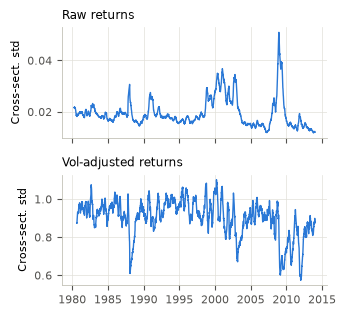

In [10]:
# Figure 1: cross-sectional standard deviation among members, 63-day average, before and after adjustment
SMALL = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
         "legend.fontsize": 8, "lines.linewidth": 1.0, "axes.linewidth": 0.6, "axes.spines.top": False,
         "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.5,
         "axes.edgecolor": "#c3c2b7", "xtick.color": "#52514e", "ytick.color": "#52514e", "pdf.fonttype": 42}
with plt.rc_context(SMALL):
    fig, ax = plt.subplots(2, 1, figsize=(3.5, 3.2), sharex=True)
    raw_dispersion = ret.where(mem).std(axis=1).rolling(63).mean()      # days t-62..t
    adj_dispersion = vadj.where(mem).std(axis=1).rolling(63).mean()     # days t-62..t
    ax[0].plot(raw_dispersion.index, raw_dispersion.values, color="#2a78d6")
    ax[0].set_title("Raw returns", loc="left")
    ax[1].plot(adj_dispersion.index, adj_dispersion.values, color="#2a78d6")
    ax[1].set_title("Vol-adjusted returns", loc="left")
    for a in ax:
        a.set_ylabel("Cross-sect. std")
    ax[1].xaxis.set_major_locator(mdates.YearLocator(5))
    ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.tight_layout()
    fig.savefig(FIGURES / "fig_t3_voladj.pdf", bbox_inches="tight")
    plt.show()

## 4. Evaluation code and harness controls

`evaluate` is the frozen scoring function: daily P&L = sum over members of prediction x unclipped next-day vol-adjusted return, annualized Sharpe, daily rank IC, holding period, correlation with the equal-weight market, and the smallest number of predictions on any day. Every configuration is recorded by `append_log`. The harness controls contain no model, so the prompt allowed running them on the test period: perfect foresight must give an absurd Sharpe, random predictions a Sharpe near zero, and an always-long portfolio a market correlation near one. The fourth row is the 5-day reversal rule on 1985-2010.

In [11]:
# Copied from src/task3_eval.py
"""Task 3 evaluation harness: Sharpe ratio and the evaluate() report.

Extracted from notebooks/task3.ipynb (cell 3). The logic is copied unchanged;
the only difference is that the notebook globals Y and mem are now arguments.

FROZEN after Phase 0: import this module, never edit it.
"""


import numpy as np
import matplotlib.pyplot as plt


def sharpe(x):
    """Annualized Sharpe ratio of a daily P&L series (252 trading days per year)."""
    return x.mean() / x.std() * np.sqrt(252)


def evaluate(P, Y, mem, start="2011-01-01", end="2013-12-31", windows=None,
             demean=False, label="", plot=True):
    """Score a prediction table P against realized next-day returns Y.

    P[t, i] is the prediction made at the close of day t for stock i.
    Y[t, i] is the vol-adjusted return of stock i on day t+1 (what P[t, i] earns).
    mem[t, i] is True if stock i is an index member on day t.

    Why: one fixed function scores every model the same way, so results are
    comparable and nobody can quietly change the metric.

    Returns (pnl, ic, out): daily P&L, daily rank IC, and a dict of summary numbers.
    """
    P = P.where(mem).loc[start:end]          # only members on day t
    Yw = Y.loc[start:end]
    if demean:                               # market-neutral: zero mean prediction each day
        P = P.sub(P.mean(axis=1), axis=0)
    valid = P.notna() & Yw.notna()
    P, Yw = P.where(valid), Yw.where(valid)

    # P&L, eq (6)
    pnl = (P * Yw).sum(axis=1, min_count=1).dropna()

    # Daily Spearman (rank IC)
    rp, ry = P.rank(axis=1), Yw.rank(axis=1)
    rp, ry = rp.sub(rp.mean(axis=1), axis=0), ry.sub(ry.mean(axis=1), axis=0)
    ic = ((rp * ry).sum(axis=1) /
          np.sqrt((rp**2).sum(axis=1) * (ry**2).sum(axis=1))).dropna()

    # Holding period, eq (7), stocks with >= 20 predictions
    counts = P.notna().sum()
    Pk = P.loc[:, counts >= 20]
    hp = (Pk.abs().iloc[1:].mean() / Pk.diff().abs().iloc[1:].mean())   # diff: P[t] - P[t-1]
    hp = hp.replace(np.inf, np.nan).dropna()

    # Correlation with equal-weight long-only portfolio of members
    mkt = Y.where(mem).loc[start:end].mean(axis=1).reindex(pnl.index)

    out = {
        "Sharpe": sharpe(pnl),
        "mean IC": ic.mean(),
        "IC t-stat": ic.mean() / ic.std() * np.sqrt(len(ic)),
        "holding period (days)": hp.mean(),
        "corr w/ market": pnl.corr(mkt),
        "min preds/day": int(valid.sum(axis=1).loc[pnl.index].min()),
    }
    print(f"===== {label} [{start} -> {end}] =====")
    for k, v in out.items():
        print(f"{k:>22}: {v:.3f}" if isinstance(v, float) else f"{k:>22}: {v}")
    print("Sharpe by year:", pnl.groupby(pnl.index.year).apply(sharpe).round(2).to_dict())
    if windows:
        for a, b in windows:
            print(f"Sharpe {a}-{b}: {sharpe(pnl.loc[a:b]):.2f}")

    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
        pnl.cumsum().plot(ax=ax[0], title=f"{label}: cumulative P&L")
        ic.cumsum().plot(ax=ax[1], title=f"{label}: cumulative rank IC")
        plt.tight_layout(); plt.show()
    return pnl, ic, out

In [12]:
# Copied from src/task3_log.py (rows kept in memory)
"""Append-only experiment log for Task 3 (results/experiment_log.csv).

Every configuration that is evaluated gets exactly one row, including
controls and failed runs. Rows are only ever appended, never edited or
deleted, so the row count is the honest number of configurations tried.
"""


from datetime import datetime


LOG_COLUMNS = [
    "exp_id", "timestamp", "phase", "model", "features", "hyperparams",
    "target_variant", "demean", "pred_smoothing_halflife", "refit_every",
    "train_window", "dev_sharpe", "dev_sharpe_1990_1999", "dev_sharpe_2000_2010",
    "mean_ic", "ic_tstat", "holding_period", "corr_market", "min_preds_per_day",
    "runtime_s", "notes",
]


EXPERIMENT_LOG = []          # one dict per evaluated configuration (in our repository: results/experiment_log.csv)


def append_log(row):
    """Append one experiment row to the log and return its exp_id.

    row is a dict whose keys are a subset of LOG_COLUMNS (missing ones are
    left blank). exp_id and timestamp are filled in here so they cannot be
    forgotten or reused. Rows are only ever appended.
    """
    unknown = set(row) - set(LOG_COLUMNS)
    assert not unknown, f"unknown log columns: {unknown}"
    full = {c: row.get(c, "") for c in LOG_COLUMNS}
    full["exp_id"] = f"E{len(EXPERIMENT_LOG) + 1:03d}"
    full["timestamp"] = datetime.now().isoformat(timespec="seconds")
    EXPERIMENT_LOG.append(full)
    return full["exp_id"]

In [13]:
# Copied from src/task3_phase0.py
"""Phase 0 harness controls (no model involved).

Three controls on the test period 2011-01-01 to 2013-12-31 check that the
frozen evaluation code behaves as expected, and the 5-day reversal baseline
is reported on 1985 to 2010 only. This is the only use of the test period
before Phase 3; it is allowed because nothing here is fitted or selected.

Run once from the repository root:  python src/task3_phase0.py
"""


import time
import numpy as np
import pandas as pd


TEST_START, TEST_END = "2011-01-01", "2013-12-31"
SEED = 42


def log_control(name, period, out, runtime_s, extra_notes="", windows=None):
    """Write one control result to the experiment log (never eligible for selection)."""
    row = {
        "phase": 0, "model": name, "features": "none", "hyperparams": "none",
        "target_variant": "none", "demean": name == "baseline_rev_5",
        "pred_smoothing_halflife": 0, "refit_every": "none", "train_window": "none",
        "mean_ic": out["mean IC"], "ic_tstat": out["IC t-stat"],
        "holding_period": out["holding period (days)"],
        "corr_market": out["corr w/ market"],
        "min_preds_per_day": out["min preds/day"], "runtime_s": round(runtime_s, 1),
        "notes": f"Phase 0 harness check on {period}, no model, not a dev result: "
                 f"Sharpe={out['Sharpe']:.3f}. {extra_notes}",
    }
    if windows:
        row.update(windows)
    return append_log(row)


def run_controls(data_dir="data"):
    """Run the four Phase 0 checks, log them, and return a pass/fail table."""
    ret, ind, meta, sig, vadj, vadj_c, Y, mem = build_targets(data_dir)
    rng = np.random.default_rng(SEED)
    idx, cols = vadj.index, vadj.columns
    period = f"{TEST_START}..{TEST_END}"
    rows = []

    # 1. Perfect foresight: predict the answer itself. Sharpe must be absurd.
    #    Threshold lowered from 50 to 10 by the group (AGENT_LOG.md, Problem 1):
    #    the harness gives 16.6, and 10 is still far beyond any real strategy.
    t0 = time.time()
    P_cheat = Y.copy()
    _, _, out = evaluate(P_cheat, Y, mem, TEST_START, TEST_END,
                         label="CHEAT (should be absurd)", plot=False)
    log_control("control_perfect_foresight", period, out, time.time() - t0)
    rows.append(["perfect foresight P = Y: Sharpe", "> 10", out["Sharpe"], out["Sharpe"] > 10])

    # 2. Pure noise: i.i.d. N(0,1). Sharpe must be near zero.
    t0 = time.time()
    P_rand = pd.DataFrame(rng.standard_normal(vadj.shape), idx, cols)
    _, _, out = evaluate(P_rand, Y, mem, TEST_START, TEST_END,
                         label="random (should be ~0)", plot=False)
    log_control("control_random_normal", period, out, time.time() - t0, "seed 42.")
    rows.append(["random N(0,1) seed 42: |Sharpe|", "< 1.5", out["Sharpe"], abs(out["Sharpe"]) < 1.5])

    # 3. Always long: must behave like the equal-weight market portfolio.
    t0 = time.time()
    P_long = pd.DataFrame(1.0, idx, cols)
    _, _, out = evaluate(P_long, Y, mem, TEST_START, TEST_END,
                         label="long-only (high market corr)", plot=False)
    log_control("control_always_long", period, out, time.time() - t0)
    rows.append(["always long P = 1: corr with market", "> 0.9",
                 out["corr w/ market"], out["corr w/ market"] > 0.9])

    # 4. 5-day reversal baseline on 1985-2010 ONLY (test period excluded).
    t0 = time.time()
    P_rev = -vadj_c.rolling(5, min_periods=3).mean()    # row t uses days t-4..t only
    windows = [("1985", "1989"), ("1990", "1994"), ("1995", "1999"),
               ("2000", "2004"), ("2005", "2010")]
    pnl, _, out = evaluate(P_rev, Y, mem, "1985-01-01", "2010-12-31", windows=windows,
                           demean=True, label="5-day reversal, 1985-2010", plot=False)
    by_window = {f"{a}-{b}": sharpe(pnl.loc[a:b]) for a, b in windows}
    log_control("baseline_rev_5", "1985-01-01..2010-12-31", out, time.time() - t0,
                "Sharpe by window: " + ", ".join(f"{k}={v:.2f}" for k, v in by_window.items()),
                windows={"dev_sharpe_1990_1999": sharpe(pnl.loc["1990":"1999"]),
                         "dev_sharpe_2000_2010": sharpe(pnl.loc["2000":"2010"])})
    rows.append(["5-day reversal 1985-2010 (demeaned): Sharpe", "report only", out["Sharpe"], ""])
    for k, v in by_window.items():
        rows.append([f"5-day reversal Sharpe {k}", "report only", v, ""])
    for k in ["mean IC", "IC t-stat", "holding period (days)", "corr w/ market", "min preds/day"]:
        rows.append([f"5-day reversal 1985-2010: {k}", "report only", out[k], ""])

    table = pd.DataFrame(rows, columns=["check", "expected", "actual", "pass"])
    return table

In [14]:
controls = run_controls("data")
check_value("E001 perfect foresight Sharpe", controls.actual[0], VERIFY["phase0"]["E001_sharpe"])
check_value("E002 random Sharpe", controls.actual[1], VERIFY["phase0"]["E002_sharpe"])
check_value("E003 always-long market correlation", controls.actual[2], VERIFY["phase0"]["E003_corr_market"])
check_value("E004 5-day reversal 1985-2010 Sharpe", controls.actual[3], VERIFY["phase0"]["E004_sharpe"])
report_checks("Section 4")
controls

/var/folders/3y/b7yfwh1s3rg_mvq_621h51m80000gn/T/ipykernel_20943/2473190883.py:61: RuntimeWarning: divide by zero encountered in scalar divide
  "IC t-stat": ic.mean() / ic.std() * np.sqrt(len(ic)),


===== CHEAT (should be absurd) [2011-01-01 -> 2013-12-31] =====
                Sharpe: 16.598
               mean IC: 1.000
             IC t-stat: inf
 holding period (days): 0.684
        corr w/ market: -0.188
         min preds/day: 496
Sharpe by year: {2011: 13.05, 2012: 22.18, 2013: 23.74}
===== random (should be ~0) [2011-01-01 -> 2013-12-31] =====
                Sharpe: 0.314
               mean IC: 0.002
             IC t-stat: 1.296
 holding period (days): 0.708
        corr w/ market: 0.056
         min preds/day: 496
Sharpe by year: {2011: 0.09, 2012: -0.26, 2013: 1.16}
===== long-only (high market corr) [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.101
               mean IC: nan
             IC t-stat: nan
 holding period (days): nan
        corr w/ market: 1.000
         min preds/day: 496
Sharpe by year: {2011: 0.06, 2012: 1.22, 2013: 2.47}
===== 5-day reversal, 1985-2010 [1985-01-01 -> 2010-12-31] =====
                Sharpe: 2.327
               mean I

,check,expected,actual,pass
0,perfect foresight P = Y: Sharpe,> 10,16.598048,True
1,"random N(0,1) seed 42: |Sharpe|",< 1.5,0.314475,True
2,always long P = 1: corr with market,> 0.9,0.999998,True
3,5-day reversal 1985-2010 (demeaned): Sharpe,report only,2.326810,
4,5-day reversal Sharpe 1985-1989,report only,3.245912,
5,5-day reversal Sharpe 1990-1994,report only,4.086938,
6,5-day reversal Sharpe 1995-1999,report only,2.591199,
7,5-day reversal Sharpe 2000-2004,report only,1.394911,
8,5-day reversal Sharpe 2005-2010,report only,1.253135,
9,5-day reversal 1985-2010: mean IC,report only,0.025506,


## 5. Features and the training-window guard

Each feature is computed per stock from data up to day t, then ranked among that day's members and scaled to [-0.5, 0.5]; a missing rank becomes 0. Return features: `rev_1`, `rev_5`, `rev_21`, `mom_12_1` (skipping the most recent month), `vol_level`, sector-relative versions of `rev_5`, `rev_21` and `mom_12_1`, and EWMA-smoothed versions (half-lives 5 and 10) of the reversal features: 18 in total. Sentiment features (from 2009-07): bullish, bearish, net, activity, their smoothed versions and an availability flag: 13 in total.

`check_training_window` is the guard: the target of row s is the return of day s+1, so a model that predicts on day t may only be trained on rows dated t-1 or earlier. Every fit below goes through it.

In [15]:
# Copied from src/task3_features.py
from pathlib import Path
import numpy as np
import pandas as pd


def rank_cs(x, mem):
    """Rank x across members on each day and scale to [-0.5, 0.5]. Missing stays NaN.

    Why: ranks put every feature on the same scale every day and remove
    the influence of extreme values. Uses row t of x and mem only.
    """
    x = x.where(mem)                    # keep members of the SAME day only
    n = x.notna().sum(axis=1)           # how many members have a value that day
    r = x.rank(axis=1)                  # 1 = smallest ... n = largest, ties get the average rank
    den = (n - 1).where(n > 1)          # one value alone cannot be ranked -> NaN
    return r.sub(1).div(den, axis=0) - 0.5


def sector_relative(x, mem, sector):
    """Subtract from x the same-day mean of x among members of the same sector.

    Why: removes moves shared by a whole sector, leaving the stock-specific
    part. sector is a Series stock id -> 2-digit GICS code. Uses row t only.
    """
    x = x.where(mem)                    # keep members of the SAME day only
    out = pd.DataFrame(np.nan, index=x.index, columns=x.columns)
    for s in sorted(sector.unique()):
        cols = sector.index[sector == s]
        sector_mean = x[cols].mean(axis=1)                      # same-day mean, no time shift
        out.loc[:, cols] = x[cols].sub(sector_mean, axis=0).values
    return out


def ewma_smooth(x, halflife):
    """EWMA over time, per stock: s[t] = a * x[t] + (1 - a) * s[t-1], a = 1 - 0.5**(1/halflife).

    Why: a smoother signal changes more slowly, so positions are held longer.
    Row t depends on rows up to and including t only.
    """
    return x.ewm(halflife=halflife, adjust=False).mean()     # recursive, looks backwards only


def rank_fill_smooth(raw, mem, halflives, smoothed):
    """Rank each raw feature, fill missing ranks with 0, and add the smoothed versions.

    smoothed lists the base features that get one smoothed version per half-life.

    Returns (feats, n_valid): feats maps feature name -> float32 table, and
    n_valid maps base feature name -> number of members with a real
    (not filled) rank on each day, used to report coverage.
    """
    feats, n_valid = {}, {}
    for name in list(raw):
        ranked = rank_cs(raw.pop(name), mem)      # pop frees the raw table once it is ranked
        n_valid[name] = ranked.notna().sum(axis=1)
        filled = ranked.fillna(0.0)               # missing -> neutral
        feats[name] = filled.astype("float32")
        if name in smoothed:
            for h in halflives:
                feats[f"{name}_hl{h}"] = ewma_smooth(filled, h).astype("float32")
    return feats, n_valid


def build_return_features(vadj_c, sig, mem, meta):
    """Build the 18 return-based features from clipped vol-adjusted returns and volatility.

    vadj_c[t] and sig[t] are both known at the close of day t.
    Returns (feats, n_valid), see rank_fill_smooth().
    """
    sector = meta["gics"].astype(str).str[:2]     # first 2 GICS digits = sector
    raw = {}
    raw["rev_1"] = vadj_c                                                   # day t only
    raw["rev_5"] = vadj_c.rolling(5, min_periods=3).mean()                  # days t-4..t
    raw["rev_21"] = vadj_c.rolling(21, min_periods=15).mean()               # days t-20..t
    # rolling(231) at row u covers days u-230..u; shift(21) puts row u = t-21 at row t,
    # so row t covers days t-251..t-21 (the most recent month is skipped)
    raw["mom_12_1"] = vadj_c.rolling(231, min_periods=231).sum().shift(21)
    raw["vol_level"] = np.log(sig)                                          # sig[t]: returns up to day t
    for name in SECTOR_FEATURES:
        raw[name + "_sec"] = sector_relative(raw[name], mem, sector)
    return rank_fill_smooth(raw, mem, RETURN_HALFLIVES, RETURN_SMOOTHED)


def build_sentiment_features(bull, bear, col_map, mem):
    """Build the 13 sentiment features on the trading days of the sentiment period.

    bullish, bearish, net = bullish - bearish, activity = bullish + bearish,
    each ranked across members, plus smoothed versions and a 0/1 flag that
    says whether the stock had any usable sentiment that day.
    Returns (feats, n_valid), see rank_fill_smooth().
    """
    trading_days = mem.index
    days = trading_days[trading_days > bull.index[0]]     # first usable day is after the first sentiment day
    keep = list(col_map)

    def to_equity_table(sent):
        """Align to trading days and relabel permno columns as equity ids."""
        aligned = align_sentiment(sent, trading_days)
        aligned = aligned[keep].rename(columns=col_map)
        return aligned.reindex(index=days, columns=mem.columns)

    b, r = to_equity_table(bull), to_equity_table(bear)
    m = mem.loc[days]
    flag = (b.notna() | r.notna()) & m                     # member with usable sentiment on day t
    raw = {"sent_bull": b, "sent_bear": r,
           "sent_net": b - r,                              # same-day difference, no time shift
           "sent_act": b + r}                              # same-day sum, no time shift
    feats, n_valid = rank_fill_smooth(raw, m, SENT_HALFLIVES, SENT_SMOOTHED)
    feats["sent_flag"] = flag.astype("float32")            # stays 0/1, not ranked
    n_valid["sent_flag"] = flag.sum(axis=1)
    return feats, n_valid

In [16]:
# Copied from src/task3_train.py
"""Task 3 training guard: no model may be trained on rows from the future.

The training target of row s is the return of day s+1, which is only known
at the close of day s+1. A model that predicts at the close of day t may
therefore only be trained on rows s <= t-1.
"""


import pandas as pd


def check_training_window(train_dates, predict_date):
    """Raise AssertionError unless every training row is strictly before predict_date.

    train_dates: the date of every training row. predict_date: the first day
    the fitted model will predict on (the refit date).
    """
    last_train = pd.DatetimeIndex(train_dates).max()
    predict_date = pd.Timestamp(predict_date)
    assert last_train < predict_date, (       # rows s must satisfy s <= t-1
        f"lookahead: training row dated {last_train.date()} is not before "
        f"the prediction date {predict_date.date()}")


def fit_model(model, X_train, y_train, train_dates, predict_date):
    """Fit a scikit-learn model after checking the training window. Returns the fitted model.

    Why: every fit in the walk-forward goes through this one function, so a
    lookahead mistake stops the run instead of producing a good-looking result.
    """
    check_training_window(train_dates, predict_date)
    model.fit(X_train, y_train)
    return model

In [17]:
# The guard in action: a fit that includes a row dated on or after the prediction day is refused.
from sklearn.linear_model import LinearRegression

days = pd.bdate_range("2005-01-03", periods=10)
X_demo, y_demo = np.arange(20.0).reshape(10, 2), np.arange(10.0)
fit_model(LinearRegression(), X_demo[:6], y_demo[:6], days[:6], days[6])
print("training rows up to", days[5].date(), "for a prediction on", days[6].date(), "-> accepted")
try:
    fit_model(LinearRegression(), X_demo[:7], y_demo[:7], days[:7], days[6])
except AssertionError as error:
    print("training rows up to", days[6].date(), "for a prediction on", days[6].date(), "-> refused:", error)

features, n_valid = build_return_features(vadj_c, sig, mem, meta)
print(len(features), "return features:", list(features))
del features

training rows up to 2005-01-10 for a prediction on 2005-01-11 -> accepted
training rows up to 2005-01-11 for a prediction on 2005-01-11 -> refused: lookahead: training row dated 2005-01-11 is not before the prediction date 2005-01-11
18 return features: ['rev_1', 'rev_1_hl5', 'rev_1_hl10', 'rev_5', 'rev_5_hl5', 'rev_5_hl10', 'rev_21', 'rev_21_hl5', 'rev_21_hl10', 'mom_12_1', 'vol_level', 'rev_5_sec', 'rev_5_sec_hl5', 'rev_5_sec_hl10', 'rev_21_sec', 'rev_21_sec_hl5', 'rev_21_sec_hl10', 'mom_12_1_sec']


## 6. Models and walk-forward

`fit_config` fits a Lasso, a least-squares regression (the Lasso with alpha = 0, used in the grid extension), a random forest or a one-hidden-layer MLP. The MLP chooses its number of epochs on the most recent 20% of the training days, because scikit-learn's own early stopping would split days at random. `walk_forward` refits every `refit_every` trading days on the rows strictly before the refit date, standardizes the features with training-window statistics, and predicts until the next refit.

In [18]:
# Copied from src/task3_models.py
"""Task 3 models: Lasso, random forest and a one-hidden-layer MLP (scikit-learn).

A model is described by a plain dict (a "spec"), for example
    {"model": "lasso", "alpha": 0.001}
    {"model": "ols"}                       (Lasso with alpha = 0, i.e. least squares)
    {"model": "rf", "max_depth": 6, "min_samples_leaf": 200}
    {"model": "mlp", "hidden": 16, "alpha": 0.0001}
fit_config() turns a spec plus training data into a fitted model. Every fit
first checks that no training row is dated on or after the prediction date.
"""


import warnings
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.neural_network import MLPRegressor


SEED = 42
MLP_MAX_EPOCHS = 30        # the number of epochs is chosen between 1 and this
MLP_HOLDOUT = 0.2          # most recent share of the training days used to choose it
MLP_BATCH = 1024


def new_mlp(spec):
    """A fresh, untrained MLP with one hidden layer (early_stopping stays off: it splits randomly)."""
    return MLPRegressor(hidden_layer_sizes=(spec["hidden"],), alpha=spec["alpha"],
                        batch_size=MLP_BATCH, random_state=SEED)


def fit_mlp(spec, X, y, dates, predict_date):
    """Fit an MLP, choosing the number of epochs on a time-ordered holdout.

    Step 1: train on the oldest 80% of the training days, one epoch at a
    time, and measure the squared error on the most recent 20% of the days.
    Step 2: train a fresh network on ALL training days for the number of
    epochs that gave the smallest holdout error.
    Why: a random split would mix future and past days inside the window.
    """
    check_training_window(dates, predict_date)
    train_days = dates.unique().sort_values()
    cut = train_days[int(len(train_days) * (1 - MLP_HOLDOUT))]    # first day of the most recent 20%
    older = np.asarray(dates < cut)                               # days before the cut: fit; from the cut on: holdout
    X_old, y_old, X_new, y_new = X[older], y[older], X[~older], y[~older]

    max_epochs = spec.get("max_epochs", MLP_MAX_EPOCHS)
    probe, errors = new_mlp(spec), []
    for epoch in range(max_epochs):
        probe.partial_fit(X_old, y_old)                           # one more pass over the older days
        errors.append(float(np.mean((probe.predict(X_new) - y_new) ** 2)))
    best_epochs = int(np.argmin(errors)) + 1

    model = new_mlp(spec)
    for epoch in range(best_epochs):
        model.partial_fit(X, y)                                   # all training days, all dated before predict_date
    return model, {"epochs": best_epochs, "holdout_mse": errors}


def fit_config(spec, X, y, dates, predict_date):
    """Fit the model described by spec. Returns (fitted model, info to record).

    X is already standardized with training-window statistics. dates holds
    the day of every training row and must all be before predict_date.
    """
    kind = spec["model"]
    if kind == "lasso":
        model = Lasso(alpha=spec["alpha"], precompute=True, max_iter=5000)
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)    # a fit that did not converge must not pass silently
            fit_model(model, X, y, dates, predict_date)
        return model, {"coef": model.coef_.copy()}
    if kind == "ols":
        model = LinearRegression()                                # the Lasso limit alpha = 0
        fit_model(model, X, y, dates, predict_date)
        return model, {"coef": model.coef_.copy()}
    if kind == "rf":
        model = RandomForestRegressor(n_estimators=100, max_depth=spec["max_depth"],
                                      min_samples_leaf=spec["min_samples_leaf"],
                                      max_features=1 / 3, n_jobs=-1, random_state=SEED)
        fit_model(model, X, y, dates, predict_date)
        return model, {"importances": model.feature_importances_.copy()}
    if kind == "mlp":
        return fit_mlp(spec, X, y, dates, predict_date)
    raise ValueError(f"unknown model: {kind}")


def lasso_alpha_grid(X, y, n=6):
    """Six log-spaced Lasso penalties derived from one training window.

    alpha_max is the smallest penalty at which every coefficient is zero:
    max_j |mean(x_j * y)| for standardized features and a centred target.
    The grid goes down from alpha_max / 2 by a factor of 2.5 per step.
    """
    X = (X - X.mean(axis=0)) / X.std(axis=0)
    alpha_max = float(np.abs(X.T @ (y - y.mean())).max() / len(y))
    return alpha_max, [alpha_max * 0.5 * 0.4 ** k for k in range(n)]

In [19]:
# Copied from src/task3_walkforward.py
"""Task 3 walk-forward engine: stack member rows, refit on the past, predict forward.

Timeline at a refit date d: the models are fitted on rows s with s <= d-1
(whose targets, the returns of days s+1 <= d, are all known at the close of
d), then they predict every day from d until the next refit date.
"""


import time
import numpy as np
import pandas as pd


def make_target(vadj_c, mem, demean=True):
    """Training target: clipped vol-adjusted return of the NEXT day, for members only.

    Why demean: the P&L of a market-neutral strategy only depends on which
    stocks beat the same-day average, so that is what the model should learn.
    """
    target = vadj_c.shift(-1).where(mem)       # row t holds the return of day t+1 (known at close of t+1)
    if demean:
        target = target.sub(target.mean(axis=1), axis=0)     # same-day mean across members
    return target


def build_panel(feats, names, target, mem, start, end):
    """Stack the member cells of days start..end into one table (one row per stock-day).

    Rows are sorted by day. Returns a dict with the feature matrix X, the
    target y, and for every row its day and stock, plus row_start: the first
    row of each day (so the rows of days a..b-1 are row_start[a]:row_start[b]).
    """
    days = mem.loc[start:end].index            # days start..end only: nothing after `end` enters the panel
    is_member = mem.loc[days].values
    row_day, row_stock = np.nonzero(is_member)               # row-major order = sorted by day
    X = np.column_stack([feats[n].loc[days].values[is_member] for n in names]).astype("float32")
    y = target.loc[days].values[is_member].astype("float64")
    row_start = np.searchsorted(row_day, np.arange(len(days) + 1))
    return {"X": X, "y": y, "names": list(names), "days": days, "columns": mem.columns,
            "row_day": row_day, "row_stock": row_stock, "dates": days[row_day],
            "row_start": row_start}


def permute_target_within_day(panel, seed=42):
    """Negative control: shuffle the targets among the stocks of each day (in place).

    This keeps every day's set of returns but destroys the link between a
    stock's features and its own return, so nothing can be learned.
    """
    rng = np.random.default_rng(seed)
    y, row_start = panel["y"], panel["row_start"]
    for k in range(len(panel["days"])):
        rows = slice(row_start[k], row_start[k + 1])         # the rows of day k only
        y[rows] = rng.permutation(y[rows])


def training_rows(panel, k_lo, k):
    """Rows of days k_lo..k-1 (strictly before day k) that have a target. Returns X, y, dates."""
    train = slice(panel["row_start"][k_lo], panel["row_start"][k])     # days k_lo..k-1 only
    has_target = ~np.isnan(panel["y"][train])
    X = panel["X"][train][has_target].astype("float64")
    return X, panel["y"][train][has_target], panel["dates"][train][has_target]


def walk_forward(panel, specs, first_pred, last_pred, refit_every, train_window,
                 subsample=None, seed=42):
    """Walk forward through time, refitting every `refit_every` trading days.

    specs: dict name -> model spec (see task3_models.fit_config). All specs
        share the same training rows at each refit, which saves time.
    train_window: number of trading days to train on, or None for expanding.
    subsample: if set, train on this many randomly chosen rows of the window.

    Returns (preds, records): preds[name] is a prediction table (days x
    stocks, NaN where no prediction), records[name] is one dict per refit.
    """
    days, row_start = panel["days"], panel["row_start"]
    k_first = days.searchsorted(pd.Timestamp(first_pred), side="left")        # first prediction day
    k_last = days.searchsorted(pd.Timestamp(last_pred), side="right") - 1     # last prediction day
    rng = np.random.default_rng(seed)
    P = {name: np.full((len(days), len(panel["columns"])), np.nan, dtype="float32") for name in specs}
    records = {name: [] for name in specs}

    for k in range(k_first, k_last + 1, refit_every):
        d = days[k]                                           # refit date = first day predicted
        k_lo = 0 if train_window is None else max(0, k - train_window)
        X_tr, y_tr, dates_tr = training_rows(panel, k_lo, k)  # rows of days k_lo..k-1: strictly before d
        k_next = min(k + refit_every, k_last + 1)
        pred = slice(row_start[k], row_start[k_next])         # rows of days k..k_next-1: d until next refit
        if subsample is not None and len(y_tr) > subsample:
            pick = rng.choice(len(y_tr), size=subsample, replace=False)
            X_tr, y_tr, dates_tr = X_tr[pick], y_tr[pick], dates_tr[pick]

        # standardize with the mean and std of the TRAINING rows only
        mu, sd = X_tr.mean(axis=0), X_tr.std(axis=0)
        sd[sd == 0] = 1.0
        X_tr = (X_tr - mu) / sd
        X_pr = (panel["X"][pred] - mu) / sd

        for name, spec in specs.items():
            t0 = time.time()
            model, info = fit_config(spec, X_tr, y_tr, dates_tr, d)    # asserts dates_tr < d
            P[name][panel["row_day"][pred], panel["row_stock"][pred]] = model.predict(X_pr)
            info.update({"refit_date": d.date(), "n_train": len(y_tr), "seconds": time.time() - t0,
                         "train_first": dates_tr.min().date(), "train_last": dates_tr.max().date()})
            records[name].append(info)

    preds = {name: pd.DataFrame(P[name], index=days, columns=panel["columns"]).iloc[k_first:k_last + 1]
             for name in specs}
    return preds, records


def smooth_predictions(P, halflife):
    """EWMA over time of each stock's predictions; halflife 0 means no smoothing.

    Why: smoother predictions change less from day to day, so positions are
    held longer. Row t uses predictions made on days up to and including t.
    """
    if halflife == 0:
        return P
    return P.ewm(halflife=halflife).mean()     # backward-looking weighted mean, NaN days are skipped

## 7. Development experiments (all 62 configurations tried before the freeze)

Development period: prediction dates 1990-01-01 to 2010-12-31. The training panel ends on 2010-12-31, and `score_and_log` refuses any evaluation that ends later. The stages run in the order they were run originally, so the experiment ids E005 to E066 match our log:

| Rows | Stage |
|---|---|
| E005-E006 | rule-based baselines (5-day reversal, 12-1 momentum) |
| E007-E024 | Lasso, 6 penalties x 3 training windows |
| E025-E030 | random forest, depth {4, 6, 8} x leaf {200, 1000} |
| E031-E034 | MLP, {16, 32} units x alpha {1e-4, 1e-2} |
| E035-E037 | Lasso with raw target; negative control (shuffled targets); positive control (features shifted one day into the future) |
| E038-E043 | sentiment study, judged on 2010 only |
| E044-E055 | post-processing of the best Lasso, forest and MLP: no demeaning, prediction smoothing |
| E056-E060 | grid extension |
| E061-E065 | delayed-execution diagnostic |
| E066 | the slow finalist: MLP E059 smoothed with a half-life of 5 days |

`evaluate` prints a short report for every configuration.

In [20]:
# Copied from src/task3_experiments.py
"""Task 3 experiment bookkeeping: score a prediction table and record everything.

Every configuration goes through score_and_log(), which calls the frozen
evaluate() on the development period and appends one row to the experiment
log. Side files keep the per-window Sharpe, the daily P&L and rank IC, and
what each model learned at each refit.
"""


import time
import numpy as np
import pandas as pd


DEV_START, DEV_END = "1990-01-01", "2010-12-31"     # development period (prediction dates)
PANEL_START = "1981-05-22"                          # first day on which all return features exist
DEV_WINDOWS = [("1990", "1994"), ("1995", "1999"), ("2000", "2004"), ("2005", "2010")]
CACHE = {}                  # prediction tables reused later, by exp_id (in our repository: results/cache/)
KEEP_PREDICTIONS = {"E005", "E012", "E029", "E033", "E058", "E059"}
DEV_WINDOWS_ROWS = []       # Sharpe per development window (in our repository: results/dev_windows.csv)
DEV_PNL = {}                # daily development P&L by exp_id (in our repository: results/dev_pnl.csv)


def score_and_log(name, P, Y, mem, row, start=DEV_START, end=DEV_END, demean=True, cache=True):
    """Evaluate prediction table P on start..end, append it to the log, return its exp_id.

    start and end are prediction dates and must not be after DEV_END: in
    Phase 2 nothing is ever evaluated on the test period.
    """
    assert pd.Timestamp(end) <= pd.Timestamp(DEV_END), "test set lockout: evaluation after 2010"
    P = P.loc[start:end]                                    # prediction dates start..end only
    pnl, ic, out = evaluate(P, Y, mem, start, end, demean=demean, label=name, plot=False)

    row = dict(row)
    row.update({
        "phase": 2, "demean": demean,
        "dev_sharpe": out["Sharpe"],
        "dev_sharpe_1990_1999": sharpe(pnl.loc["1990":"1999"]) if start < "2000" else "",
        "dev_sharpe_2000_2010": sharpe(pnl.loc["2000":"2010"]),
        "mean_ic": out["mean IC"], "ic_tstat": out["IC t-stat"],
        "holding_period": out["holding period (days)"], "corr_market": out["corr w/ market"],
        "min_preds_per_day": out["min preds/day"],
    })
    exp_id = append_log(row)

    windows = {"exp_id": exp_id, "name": name, "start": start, "end": end, "dev_sharpe": out["Sharpe"]}
    for a, b in DEV_WINDOWS:
        in_window = pnl.loc[a:b]
        windows[f"sharpe_{a}_{b}"] = sharpe(in_window) if len(in_window) > 1 else np.nan
    DEV_WINDOWS_ROWS.append(windows)
    DEV_PNL[exp_id] = pnl
    if cache and exp_id in KEEP_PREDICTIONS:
        CACHE[exp_id] = P.astype("float32")
    return exp_id


def load_cached(exp_id):
    """Load the development-period prediction table of an earlier experiment."""
    return CACHE[exp_id]


def run_group(panel, specs, rows, Y, mem, refit_every, train_window,
              start=DEV_START, end=DEV_END, subsample=None):
    """Walk forward for a group of specs that share training data, then score and log each.

    rows: dict name -> the descriptive log columns of that configuration.
    If the walk-forward crashes, every configuration of the group is still
    logged, marked FAILED, so that no attempt disappears from the record.
    Returns dict name -> exp_id.
    """
    t0 = time.time()
    try:
        preds, records = walk_forward(panel, specs, start, end, refit_every, train_window, subsample)
    except Exception as error:
        for name in specs:
            failed = dict(rows[name])
            failed.update({"phase": 2, "runtime_s": round(time.time() - t0, 1),
                           "notes": f"FAILED: {type(error).__name__}: {error} | " + failed.get("notes", "")})
            append_log(failed)
        raise
    exp_ids = {}
    for name in specs:
        row = dict(rows[name])
        row["runtime_s"] = round(sum(rec["seconds"] for rec in records[name]), 1)
        exp_ids[name] = score_and_log(name, preds[name], Y, mem, row, start, end)
        print(f"   -> logged {name} as {exp_ids[name]}", flush=True)
    return exp_ids

In [21]:
# Copied from src/task3_phase2.py
"""Phase 2, part 1: baselines and the Lasso grid on the development period.

Development period = prediction dates 1990-01-01 to 2010-12-31. The panel
ends on 2010-12-31, so no test-period row can enter training or scoring.

Run from the repository root, one stage at a time:
    python src/task3_phase2.py baselines
    python src/task3_phase2.py lasso
"""


import json
import sys


TARGET_DEMEANED = "next-day vadj_c, demeaned per day"
TRAIN_WINDOWS = {"3y": 756, "5y": 1260, "expanding": None}     # trading days (252 per year)
LASSO_REFIT, SLOW_REFIT = 63, 252                              # refit every N trading days
LASSO_ALPHA_GRID = {}       # filled by stage_lasso (in our repository: results/lasso_alpha_grid.json)


def load_world(data_dir="data"):
    """Load the frozen pipeline outputs into one dict."""
    ret, ind, meta, sig, vadj, vadj_c, Y, mem = build_targets(data_dir)
    return {"ret": ret, "meta": meta, "sig": sig, "vadj_c": vadj_c, "Y": Y, "mem": mem}


def return_panel(world, demean_target=True):
    """Stacked member rows, 18 return features, from PANEL_START to DEV_END."""
    feats, _ = build_return_features(world["vadj_c"], world["sig"], world["mem"], world["meta"])
    target = make_target(world["vadj_c"], world["mem"], demean=demean_target)
    return build_panel(feats, list(feats), target, world["mem"], PANEL_START, DEV_END)


def model_row(model, hyperparams, window, refit_every, features="return_18",
              target=TARGET_DEMEANED, notes=""):
    """The descriptive log columns shared by all fitted configurations."""
    return {"model": model, "features": features, "hyperparams": hyperparams,
            "target_variant": target, "pred_smoothing_halflife": 0,
            "refit_every": refit_every, "train_window": window, "notes": notes}


def stage_baselines(world):
    """Two rule-based baselines: nothing is fitted."""
    vadj_c, Y, mem = world["vadj_c"], world["Y"], world["mem"]
    P_rev = -vadj_c.rolling(5, min_periods=3).mean()                     # row t uses days t-4..t
    # rolling(231) at row u covers u-230..u; shift(21) moves it to row t = u+21: days t-251..t-21
    P_mom = vadj_c.rolling(231, min_periods=231).sum().shift(21)
    for name, P, rule in [("baseline_rev_5", P_rev, "minus mean of vadj_c over t-4..t"),
                          ("baseline_mom_12_1", P_mom, "sum of vadj_c over t-251..t-21")]:
        row = {"model": name, "features": "none", "hyperparams": "none", "target_variant": "none",
               "pred_smoothing_halflife": 0, "refit_every": "none", "train_window": "none",
               "runtime_s": 0, "notes": "rule-based baseline: " + rule}
        print(name, "->", score_and_log(name, P, Y, mem, row))


def stage_lasso(world):
    """Lasso: 6 penalties x 3 training windows = 18 configurations."""
    panel = return_panel(world)
    # penalty grid from the FIRST expanding training window only (rows before the first dev day)
    k_first = panel["days"].searchsorted(DEV_START)
    X0, y0, dates0 = training_rows(panel, 0, k_first)
    alpha_max, alphas = lasso_alpha_grid(X0, y0)
    LASSO_ALPHA_GRID.update({"alpha_max": alpha_max, "alphas": alphas, "window_first": str(dates0.min().date()),
                             "window_last": str(dates0.max().date()), "n_rows": len(y0)})
    print("alpha_max", alpha_max, "grid", alphas, flush=True)

    for label, n_days in TRAIN_WINDOWS.items():
        specs, rows = {}, {}
        for i, alpha in enumerate(alphas):
            name = f"lasso_{label}_a{i}"
            specs[name] = {"model": "lasso", "alpha": alpha}
            rows[name] = model_row("lasso", f"alpha={alpha:.3e} (grid index {i})", label, LASSO_REFIT)
        print("window", label, flush=True)
        run_group(panel, specs, rows, world["Y"], world["mem"], LASSO_REFIT, n_days)

In [22]:
# Copied from src/task3_phase2b.py
"""Phase 2, part 2: random forest, MLP, controls, sentiment and post-processing.

The choices at the top of this file were made from development-period
results only (1990-2010) and are explained in results/AGENT_LOG.md.

Run from the repository root, one stage at a time:
    python src/task3_phase2b.py rf | mlp | variants | sentiment | post | extension | delay | slow
"""


import json
import sys
import pandas as pd


# ---- choices made from development results (see AGENT_LOG.md, Phase 2) ----
BEST_LASSO_WINDOW = "3y"            # training window of the chosen Lasso
BEST_LASSO_ALPHA = 5                # its index in the alpha grid (the smallest penalty)
SLOW_WINDOW = "3y"                  # training window used for random forest and MLP
MLP_SUBSAMPLE = None                # rows per MLP fit (None = all rows of the window)
SENT_ALPHAS = [5, 2]                # two alpha grid indices for the sentiment study
BEST = {"lasso": "E012", "rf": "E029", "mlp": "E033"}     # best of each family (post-processing)
# ---------------------------------------------------------------------------
# Finalists after the grid extension (rule: replace only if the extension beats the finalist
# by more than 0.22 in development Sharpe). "E033+hl5" = predictions of E033 smoothed, half-life 5.
# This is the value used when the delayed-execution diagnostic (E061-E065) was run; the group
# later fixed the slow finalist as E059 smoothed (E066).
FINALISTS = {"lasso": "E012", "rf": "E058", "mlp": "E059", "mlp_slow": "E033+hl5"}
RF_SUBSAMPLE = 200_000
SENT_DEV_START = "2010-01-01"       # sentiment models are judged on 2010 only


def alpha_grid():
    """The Lasso penalty grid saved by the lasso stage."""
    return LASSO_ALPHA_GRID["alphas"]


def stage_rf(world):
    """Random forest: max_depth {4, 6, 8} x min_samples_leaf {200, 1000} = 6 configurations."""
    panel = return_panel(world)
    specs, rows = {}, {}
    for depth in [4, 6, 8]:
        for leaf in [200, 1000]:
            name = f"rf_{SLOW_WINDOW}_d{depth}_l{leaf}"
            specs[name] = {"model": "rf", "max_depth": depth, "min_samples_leaf": leaf}
            rows[name] = model_row(
                "rf", f"n_estimators=100, max_depth={depth}, min_samples_leaf={leaf}, "
                      f"max_features=1/3, subsample={RF_SUBSAMPLE} rows", SLOW_WINDOW, SLOW_REFIT)
    run_group(panel, specs, rows, world["Y"], world["mem"], SLOW_REFIT,
              TRAIN_WINDOWS[SLOW_WINDOW], subsample=RF_SUBSAMPLE)


def stage_mlp(world):
    """MLP: hidden units {16, 32} x alpha {1e-4, 1e-2} = 4 configurations."""
    panel = return_panel(world)
    for hidden in [16, 32]:              # one group per size, so a crash loses less work
        specs, rows = {}, {}
        for alpha in [1e-4, 1e-2]:
            name = f"mlp_{SLOW_WINDOW}_h{hidden}_a{alpha:g}"
            specs[name] = {"model": "mlp", "hidden": hidden, "alpha": alpha}
            rows[name] = model_row(
                "mlp", f"hidden=({hidden},), alpha={alpha:g}, batch=1024, epochs chosen in 1..30 on "
                       f"most recent 20% of training days, subsample={MLP_SUBSAMPLE}",
                SLOW_WINDOW, SLOW_REFIT)
        run_group(panel, specs, rows, world["Y"], world["mem"], SLOW_REFIT,
                  TRAIN_WINDOWS[SLOW_WINDOW], subsample=MLP_SUBSAMPLE)


def stage_variants(world):
    """Chosen Lasso with a raw target, plus the negative and the positive control."""
    alpha = alpha_grid()[BEST_LASSO_ALPHA]
    n_days = TRAIN_WINDOWS[BEST_LASSO_WINDOW]
    spec = {"model": "lasso", "alpha": alpha}
    hyper = f"alpha={alpha:.3e} (grid index {BEST_LASSO_ALPHA})"
    Y, mem = world["Y"], world["mem"]

    def run_one(name, panel, row):
        run_group(panel, {name: spec}, {name: row}, Y, mem, LASSO_REFIT, n_days)

    # 1. target variant: raw next-day return, not demeaned
    panel = return_panel(world, demean_target=False)
    run_one("lasso_raw_target", panel,
            model_row("lasso", hyper, BEST_LASSO_WINDOW, LASSO_REFIT, target="next-day vadj_c, raw"))

    # 2. negative control: training targets shuffled among the stocks of each day
    panel = return_panel(world)
    permute_target_within_day(panel)
    run_one("control_negative_permuted_target", panel,
            model_row("control_negative", hyper, BEST_LASSO_WINDOW, LASSO_REFIT,
                      target="demeaned target PERMUTED across stocks within each day",
                      notes="CONTROL, not eligible: expect Sharpe near 0"))

    # 3. positive control: every feature shifted one day into the FUTURE on purpose
    feats, _ = build_return_features(world["vadj_c"], world["sig"], mem, world["meta"])
    leaky = {name: table.shift(-1).fillna(0.0) for name, table in feats.items()}   # LEAK: row t holds day t+1
    del feats
    panel = build_panel(leaky, list(leaky), make_target(world["vadj_c"], mem), mem, PANEL_START, DEV_END)
    run_one("control_positive_leaky_features", panel,
            model_row("control_positive", hyper, BEST_LASSO_WINDOW, LASSO_REFIT,
                      features="return_18 shifted one day into the future (deliberate leak)",
                      notes="CONTROL, not eligible: expect a dramatic jump in Sharpe"))


def stage_sentiment(world):
    """Sentiment study on 2010 only: 6 configurations, expanding training from 2009-07."""
    mem, Y = world["mem"], world["Y"]
    ret_feats, _ = build_return_features(world["vadj_c"], world["sig"], mem, world["meta"])
    bull, bear = load_sentiment()
    col_map, _ = sentiment_column_map(bull.columns, world["ret"], bull.index[0])
    sent_feats, _ = build_sentiment_features(bull, bear, col_map, mem)
    first_day = sent_feats["sent_bull"].index[0]                 # 2009-07-13, first usable sentiment
    feats = dict(ret_feats)
    feats.update(sent_feats)
    target = make_target(world["vadj_c"], mem)
    sets = {"return_18": list(ret_feats), "sentiment_13": list(sent_feats),
            "return_18+sentiment_13": list(ret_feats) + list(sent_feats)}
    panels = {label: build_panel(feats, names, target, mem, first_day, DEV_END)
              for label, names in sets.items()}
    note = "sentiment study: dev window is 2010 only (1 year), training starts 2009-07-13"
    alphas = alpha_grid()

    def run_one(name, label, spec, row, refit, subsample=None):
        row["features"], row["notes"] = label, note
        run_group(panels[label], {name: spec}, {name: row}, Y, mem, refit, None,
                  start=SENT_DEV_START, subsample=subsample)

    for i in SENT_ALPHAS:
        for label in ["return_18", "return_18+sentiment_13"]:
            run_one(f"sent_lasso_{label}_a{i}", label, {"model": "lasso", "alpha": alphas[i]},
                    model_row("lasso", f"alpha={alphas[i]:.3e} (grid index {i})", "expanding from 2009-07",
                              LASSO_REFIT), LASSO_REFIT)
    i = SENT_ALPHAS[0]
    run_one(f"sent_lasso_sentiment_13_a{i}", "sentiment_13", {"model": "lasso", "alpha": alphas[i]},
            model_row("lasso", f"alpha={alphas[i]:.3e} (grid index {i})", "expanding from 2009-07",
                      LASSO_REFIT), LASSO_REFIT)
    run_one("sent_rf_return_18+sentiment_13", "return_18+sentiment_13",
            {"model": "rf", "max_depth": 4, "min_samples_leaf": 1000},
            model_row("rf", "n_estimators=100, max_depth=4, min_samples_leaf=1000, max_features=1/3",
                      "expanding from 2009-07", SLOW_REFIT), SLOW_REFIT, subsample=RF_SUBSAMPLE)


def stage_post(world):
    """Post-processing of the best Lasso, RF and MLP: demean off, and prediction smoothing."""
    log = pd.DataFrame(EXPERIMENT_LOG).astype(str).set_index("exp_id")
    keep = ["model", "features", "hyperparams", "target_variant", "refit_every", "train_window"]
    for name, exp_id in BEST.items():
        P = load_cached(exp_id)
        row = log.loc[exp_id, keep].to_dict()
        row.update({"runtime_s": 0, "pred_smoothing_halflife": 0,
                    "notes": f"post-processing of {exp_id}: evaluated WITHOUT daily demeaning"})
        score_and_log(f"{name}_nodemean", P, world["Y"], world["mem"], row, demean=False, cache=False)
        for halflife in [2, 5, 10]:
            row.update({"pred_smoothing_halflife": halflife,
                        "notes": f"post-processing of {exp_id}: predictions smoothed over time"})
            score_and_log(f"{name}_hl{halflife}", smooth_predictions(P, halflife), world["Y"],
                          world["mem"], row, demean=True, cache=False)


def stage_extension(world):
    """Grid extension asked by the group: 5 configurations just beyond the edges of the grids."""
    panel = return_panel(world)
    Y, mem, n_days = world["Y"], world["mem"], TRAIN_WINDOWS[SLOW_WINDOW]
    note = "grid extension: "

    run_group(panel, {"ext_lasso_3y_ols": {"model": "ols"}},
              {"ext_lasso_3y_ols": model_row("lasso", "alpha=0 (ordinary least squares)", "3y", LASSO_REFIT,
                                             notes=note + "Lasso limit alpha = 0")},
              Y, mem, LASSO_REFIT, TRAIN_WINDOWS["3y"])

    specs, rows = {}, {}
    for depth in [10, 12]:
        name = f"ext_rf_3y_d{depth}_l200"
        specs[name] = {"model": "rf", "max_depth": depth, "min_samples_leaf": 200}
        rows[name] = model_row("rf", f"n_estimators=100, max_depth={depth}, min_samples_leaf=200, "
                                     f"max_features=1/3, subsample={RF_SUBSAMPLE} rows",
                               SLOW_WINDOW, SLOW_REFIT, notes=note + "deeper trees than the grid")
    run_group(panel, specs, rows, Y, mem, SLOW_REFIT, n_days, subsample=RF_SUBSAMPLE)

    specs = {"ext_mlp_3y_h32_cap60": {"model": "mlp", "hidden": 32, "alpha": 1e-4, "max_epochs": 60},
             "ext_mlp_3y_h64": {"model": "mlp", "hidden": 64, "alpha": 1e-4}}
    rows = {"ext_mlp_3y_h32_cap60": model_row(
                "mlp", "hidden=(32,), alpha=0.0001, batch=1024, epochs chosen in 1..60 on most recent "
                       "20% of training days", SLOW_WINDOW, SLOW_REFIT, notes=note + "epoch cap 60 instead of 30"),
            "ext_mlp_3y_h64": model_row(
                "mlp", "hidden=(64,), alpha=0.0001, batch=1024, epochs chosen in 1..30 on most recent "
                       "20% of training days", SLOW_WINDOW, SLOW_REFIT, notes=note + "64 hidden units")}
    run_group(panel, specs, rows, Y, mem, SLOW_REFIT, n_days)


def stage_delay(world):
    """Diagnostic: what if every position were entered one day late? Not a selection criterion."""
    vadj_c, Y, mem = world["vadj_c"], world["Y"], world["mem"]
    tables = {name: load_cached(exp_id) for name, exp_id in FINALISTS.items() if "+" not in exp_id}
    for name, exp_id in FINALISTS.items():
        if "+" in exp_id:                                        # "E033+hl5": a smoothed finalist
            source, halflife = exp_id.split("+hl")
            tables[name] = smooth_predictions(load_cached(source), int(halflife))
    tables["baseline_rev_5"] = load_cached("E005")
    for name, P in tables.items():
        delayed = P.shift(1)                                     # row t holds the prediction made on day t-1
        row = {"model": "diagnostic_delayed_execution", "features": "see source", "hyperparams": "see source",
               "target_variant": "see source", "pred_smoothing_halflife": "see source",
               "refit_every": "see source", "train_window": "see source", "runtime_s": 0,
               "notes": f"DIAGNOSTIC, not eligible: predictions of {name} "
                        f"({FINALISTS.get(name, 'E005')}) used one day late, P.shift(1)"}
        score_and_log(f"delay1_{name}", delayed, Y, mem, row, cache=False)


def stage_slow(world):
    """The slow finalist: predictions of the MLP finalist E059 smoothed with a half-life of 5 days."""
    log = pd.DataFrame(EXPERIMENT_LOG).astype(str).set_index("exp_id")
    keep = ["model", "features", "hyperparams", "target_variant", "refit_every", "train_window"]
    row = log.loc["E059", keep].to_dict()
    row.update({"runtime_s": 0, "pred_smoothing_halflife": 5,
                "notes": "post-processing of E059: predictions smoothed over time; slow finalist "
                         "fixed by the group regardless of its development Sharpe"})
    P = smooth_predictions(load_cached("E059"), 5)           # row t uses predictions of days <= t
    score_and_log("mlp_cap60_hl5", P, world["Y"], world["mem"], row, demean=True, cache=False)

In [23]:
world = load_world("data")
STAGE_SECONDS = {}


def run_stage(stage):
    """Run one development stage and record how long it took."""
    t0 = time.time()
    stage(world)
    STAGE_SECONDS[stage.__name__] = time.time() - t0
    print(f"{stage.__name__}: {STAGE_SECONDS[stage.__name__] / 60:.1f} minutes, log now has {len(EXPERIMENT_LOG)} rows")


run_stage(stage_baselines)

===== baseline_rev_5 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 2.176
               mean IC: 0.023
             IC t-stat: 14.174
 holding period (days): 1.562
        corr w/ market: 0.168
         min preds/day: 493
Sharpe by year: {1990: 0.58, 1991: 6.12, 1992: 6.29, 1993: 2.85, 1994: 6.22, 1995: 3.47, 1996: 4.8, 1997: 3.49, 1998: 0.88, 1999: 1.95, 2000: 2.28, 2001: 0.91, 2002: 0.85, 2003: 1.47, 2004: 1.92, 2005: 1.8, 2006: 1.67, 2007: 1.05, 2008: 1.23, 2009: 1.45, 2010: 1.21}
baseline_rev_5 -> E005
===== baseline_mom_12_1 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 0.520
               mean IC: 0.012
             IC t-stat: 6.677
 holding period (days): 10.907
        corr w/ market: 0.131
         min preds/day: 487
Sharpe by year: {1990: 2.17, 1991: 1.74, 1992: -0.13, 1993: 0.85, 1994: -1.03, 1995: 1.75, 1996: 0.27, 1997: 0.84, 1998: 2.27, 1999: 1.09, 2000: -0.21, 2001: -0.17, 2002: 0.97, 2003: -1.85, 2004: 0.41, 2005: 1.99, 2006: -0.95, 2007: 1.75, 20

In [24]:
# Lasso grid (about 5 minutes)
run_stage(stage_lasso)

alpha_max 0.03314537633673122 grid [0.01657268816836561, 0.006629075267346245, 0.0026516301069384983, 0.0010606520427753994, 0.00042426081711015973, 0.0001697043268440639]
window 3y
===== lasso_3y_a0 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 2.471
               mean IC: 0.026
             IC t-stat: 14.306
 holding period (days): 2.985201120376587
        corr w/ market: 0.130
         min preds/day: 493
Sharpe by year: {1990: 0.03, 1991: 2.68, 1992: 1.75, 1993: 4.28, 1994: 6.51, 1995: 4.21, 1996: 4.47, 1997: 4.59, 1998: 1.38, 1999: 1.84, 2000: 1.86, 2001: 1.91, 2002: 1.77, 2003: 3.16, 2004: 2.6, 2005: 0.99, 2006: -1.64, 2007: 0.2, 2008: 0.13, 2009: -1.83, 2010: -1.11}
   -> logged lasso_3y_a0 as E007
===== lasso_3y_a1 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 3.299
               mean IC: 0.026
             IC t-stat: 15.568
 holding period (days): 1.4879534244537354
        corr w/ market: 0.249
         min preds/day: 493
Sharpe by year: {1990: 3.64, 1

In [25]:
# random forest (about 30 minutes)
run_stage(stage_rf)

===== rf_3y_d4_l200 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 4.555
               mean IC: 0.030
             IC t-stat: 20.247
 holding period (days): 1.2561832666397095
        corr w/ market: 0.212
         min preds/day: 493
Sharpe by year: {1990: 4.74, 1991: 12.65, 1992: 9.23, 1993: 8.18, 1994: 7.23, 1995: 6.41, 1996: 7.06, 1997: 6.43, 1998: 3.22, 1999: 3.74, 2000: 3.87, 2001: 2.61, 2002: 3.66, 2003: 3.7, 2004: 3.53, 2005: 2.4, 2006: 3.83, 2007: 1.13, 2008: 0.96, 2009: 1.7, 2010: 2.95}
   -> logged rf_3y_d4_l200 as E025
===== rf_3y_d4_l1000 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 4.473
               mean IC: 0.030
             IC t-stat: 20.681
 holding period (days): 1.2840691804885864
        corr w/ market: 0.212
         min preds/day: 493
Sharpe by year: {1990: 4.61, 1991: 12.96, 1992: 8.98, 1993: 7.81, 1994: 7.25, 1995: 6.3, 1996: 7.11, 1997: 6.24, 1998: 3.05, 1999: 3.73, 2000: 3.8, 2001: 2.53, 2002: 3.57, 2003: 3.51, 2004: 3.53, 2005: 2.44,

In [26]:
# MLP (about 15 minutes)
run_stage(stage_mlp)

===== mlp_3y_h16_a0.0001 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 4.883
               mean IC: 0.032
             IC t-stat: 23.594
 holding period (days): 1.3360557556152344
        corr w/ market: 0.266
         min preds/day: 493
Sharpe by year: {1990: 3.89, 1991: 12.57, 1992: 9.28, 1993: 9.96, 1994: 8.99, 1995: 7.7, 1996: 7.16, 1997: 7.58, 1998: 4.33, 1999: 3.41, 2000: 2.73, 2001: 3.86, 2002: 2.97, 2003: 3.97, 2004: 4.17, 2005: 3.43, 2006: 3.56, 2007: 2.39, 2008: 1.13, 2009: 3.98, 2010: 2.06}
   -> logged mlp_3y_h16_a0.0001 as E031
===== mlp_3y_h16_a0.01 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 4.887
               mean IC: 0.032
             IC t-stat: 23.654
 holding period (days): 1.3393359184265137
        corr w/ market: 0.266
         min preds/day: 493
Sharpe by year: {1990: 4.17, 1991: 12.57, 1992: 9.3, 1993: 10.04, 1994: 9.01, 1995: 7.66, 1996: 7.2, 1997: 7.48, 1998: 4.32, 1999: 3.26, 2000: 2.69, 2001: 3.86, 2002: 2.96, 2003: 4.02, 2004: 4.

In [27]:
# raw target and the two controls
run_stage(stage_variants)

===== lasso_raw_target [1990-01-01 -> 2010-12-31] =====
                Sharpe: 4.064
               mean IC: 0.030
             IC t-stat: 19.245
 holding period (days): 1.395829200744629
        corr w/ market: 0.289
         min preds/day: 493
Sharpe by year: {1990: 5.07, 1991: 10.12, 1992: 7.43, 1993: 7.72, 1994: 7.29, 1995: 6.22, 1996: 6.17, 1997: 6.89, 1998: 2.82, 1999: 2.32, 2000: 2.0, 2001: 2.37, 2002: 2.29, 2003: 3.66, 2004: 4.3, 2005: 3.26, 2006: 4.29, 2007: 1.09, 2008: 0.35, 2009: 1.35, 2010: 1.65}
   -> logged lasso_raw_target as E035
===== control_negative_permuted_target [1990-01-01 -> 2010-12-31] =====
                Sharpe: -0.024
               mean IC: 0.003
             IC t-stat: 1.664
 holding period (days): 1.713179111480713
        corr w/ market: -0.016
         min preds/day: 493
Sharpe by year: {1990: 1.29, 1991: 3.49, 1992: 2.46, 1993: 2.16, 1994: -3.39, 1995: 0.53, 1996: 2.24, 1997: -0.64, 1998: -2.71, 1999: 1.08, 2000: 0.82, 2001: -1.93, 2002: 0.71, 2003: 

In [28]:
# sentiment study
run_stage(stage_sentiment)

===== sent_lasso_return_18_a5 [2010-01-01 -> 2010-12-31] =====
                Sharpe: 0.425
               mean IC: 0.003
             IC t-stat: 0.366
 holding period (days): 2.1013681888580322
        corr w/ market: -0.105
         min preds/day: 498
Sharpe by year: {2010: 0.43}
   -> logged sent_lasso_return_18_a5 as E038
===== sent_lasso_return_18+sentiment_13_a5 [2010-01-01 -> 2010-12-31] =====
                Sharpe: 0.315
               mean IC: 0.003
             IC t-stat: 0.383
 holding period (days): 1.9152958393096924
        corr w/ market: -0.101
         min preds/day: 498
Sharpe by year: {2010: 0.32}
   -> logged sent_lasso_return_18+sentiment_13_a5 as E039
===== sent_lasso_return_18_a2 [2010-01-01 -> 2010-12-31] =====
                Sharpe: 0.367
               mean IC: 0.003
             IC t-stat: 0.436
 holding period (days): 2.31266713142395
        corr w/ market: -0.156
         min preds/day: 498
Sharpe by year: {2010: 0.37}
   -> logged sent_lasso_return_18_

In [29]:
# post-processing
run_stage(stage_post)

===== lasso_nodemean [1990-01-01 -> 2010-12-31] =====
                Sharpe: 4.063
               mean IC: 0.030
             IC t-stat: 19.240
 holding period (days): 1.39467453956604
        corr w/ market: 0.289
         min preds/day: 493
Sharpe by year: {1990: 5.07, 1991: 10.13, 1992: 7.44, 1993: 7.72, 1994: 7.27, 1995: 6.21, 1996: 6.16, 1997: 6.86, 1998: 2.81, 1999: 2.32, 2000: 2.0, 2001: 2.39, 2002: 2.29, 2003: 3.66, 2004: 4.31, 2005: 3.29, 2006: 4.29, 2007: 1.09, 2008: 0.35, 2009: 1.33, 2010: 1.66}
===== lasso_hl2 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 2.857
               mean IC: 0.020
             IC t-stat: 12.937
 holding period (days): 3.552
        corr w/ market: 0.303
         min preds/day: 493
Sharpe by year: {1990: 3.84, 1991: 6.0, 1992: 3.63, 1993: 4.24, 1994: 5.02, 1995: 5.21, 1996: 5.51, 1997: 4.4, 1998: 2.92, 1999: 2.09, 2000: 0.83, 2001: 2.72, 2002: 1.58, 2003: 2.63, 2004: 3.57, 2005: 1.83, 2006: 3.33, 2007: 1.02, 2008: -0.17, 2009: 0.16, 201

In [30]:
# grid extension (about 30 minutes)
run_stage(stage_extension)

===== ext_lasso_3y_ols [1990-01-01 -> 2010-12-31] =====
                Sharpe: 4.199
               mean IC: 0.031
             IC t-stat: 20.109
 holding period (days): 1.3996367454528809
        corr w/ market: 0.281
         min preds/day: 493
Sharpe by year: {1990: 5.12, 1991: 10.31, 1992: 7.72, 1993: 7.81, 1994: 7.57, 1995: 6.43, 1996: 6.4, 1997: 7.1, 1998: 2.82, 1999: 2.54, 2000: 2.08, 2001: 2.48, 2002: 2.4, 2003: 3.74, 2004: 4.44, 2005: 3.83, 2006: 4.37, 2007: 1.24, 2008: 0.45, 2009: 1.62, 2010: 1.68}
   -> logged ext_lasso_3y_ols as E056
===== ext_rf_3y_d10_l200 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 5.682
               mean IC: 0.033
             IC t-stat: 26.106
 holding period (days): 1.111831784248352
        corr w/ market: 0.241
         min preds/day: 493
Sharpe by year: {1990: 7.11, 1991: 14.71, 1992: 11.37, 1993: 10.6, 1994: 8.58, 1995: 8.27, 1996: 8.6, 1997: 7.67, 1998: 4.01, 1999: 4.46, 2000: 4.55, 2001: 3.52, 2002: 4.25, 2003: 4.24, 2004: 4.66, 

In [31]:
# delayed-execution diagnostic
run_stage(stage_delay)

===== delay1_lasso [1990-01-01 -> 2010-12-31] =====
                Sharpe: 2.703
               mean IC: 0.017
             IC t-stat: 11.668
 holding period (days): 1.39473295211792
        corr w/ market: 0.264
         min preds/day: 492
Sharpe by year: {1990: 4.06, 1991: 3.86, 1992: 1.87, 1993: 2.99, 1994: 5.17, 1995: 4.82, 1996: 5.69, 1997: 3.63, 1998: 3.21, 1999: 2.48, 2000: 1.51, 2001: 2.85, 2002: 1.06, 2003: 2.74, 2004: 3.77, 2005: 2.43, 2006: 3.06, 2007: 1.29, 2008: -0.22, 2009: -0.19, 2010: 0.8}
===== delay1_rf [1990-01-01 -> 2010-12-31] =====
                Sharpe: 3.811
               mean IC: 0.018
             IC t-stat: 15.767
 holding period (days): 1.0879522562026978
        corr w/ market: 0.228
         min preds/day: 492
Sharpe by year: {1990: 5.4, 1991: 6.07, 1992: 3.97, 1993: 4.48, 1994: 5.77, 1995: 6.28, 1996: 7.18, 1997: 3.9, 1998: 3.24, 1999: 3.29, 2000: 4.15, 2001: 4.45, 2002: 2.42, 2003: 2.71, 2004: 3.62, 2005: 2.45, 2006: 3.26, 2007: 2.15, 2008: 1.05, 2009

In [32]:
# the slow finalist
run_stage(stage_slow)

===== mlp_cap60_hl5 [1990-01-01 -> 2010-12-31] =====
                Sharpe: 2.531
               mean IC: 0.019
             IC t-stat: 12.509
 holding period (days): 5.562
        corr w/ market: 0.253
         min preds/day: 493
Sharpe by year: {1990: 3.39, 1991: 6.03, 1992: 3.57, 1993: 4.51, 1994: 4.14, 1995: 5.11, 1996: 5.18, 1997: 4.15, 1998: 2.12, 1999: 1.75, 2000: 0.22, 2001: 3.27, 2002: 2.17, 2003: 2.89, 2004: 1.96, 2005: 1.61, 2006: 1.84, 2007: 2.26, 2008: 0.36, 2009: 3.19, 2010: 1.42}
stage_slow: 0.1 minutes, log now has 66 rows


In [33]:
log = pd.DataFrame(EXPERIMENT_LOG).set_index("exp_id")
windows = pd.DataFrame(DEV_WINDOWS_ROWS).set_index("exp_id")
dev_ids = [f"E{i:03d}" for i in range(5, 67)]
assert list(windows.index) == dev_ids, "the development ids do not line up with the log"
for exp_id in dev_ids:
    recorded = VERIFY["dev"][exp_id]
    assert windows.name[exp_id] == recorded["name"], (exp_id, windows.name[exp_id], recorded["name"])
    check_value(f"{exp_id} dev Sharpe", log.dev_sharpe[exp_id], recorded["dev_sharpe"])
    check_value(f"{exp_id} holding period", log.holding_period[exp_id], recorded["holding_period"])
    for column in ["sharpe_1990_1994", "sharpe_1995_1999", "sharpe_2000_2004", "sharpe_2005_2010"]:
        check_value(f"{exp_id} {column}", windows.loc[exp_id, column], recorded[column])
report_checks("Section 7")

WINDOW_COLUMNS = ["sharpe_1990_1994", "sharpe_1995_1999", "sharpe_2000_2004", "sharpe_2005_2010"]
dev_table = windows[["name", "dev_sharpe"] + WINDOW_COLUMNS].join(
    log[["model", "pred_smoothing_halflife", "demean", "holding_period", "min_preds_per_day"]])
print("Development table: all 62 configurations, in the order they were run (prediction dates 1990-2010;"
      " the sentiment rows E038-E043 cover 2010 only)")
dev_table[["name", "model", "dev_sharpe"] + WINDOW_COLUMNS + ["holding_period", "min_preds_per_day"]].round(3)

Section 7: all 387 numbers checked so far match the recorded values to 4 decimals
Development table: all 62 configurations, in the order they were run (prediction dates 1990-2010; the sentiment rows E038-E043 cover 2010 only)


,name,model,dev_sharpe,sharpe_1990_1994,sharpe_1995_1999,sharpe_2000_2004,sharpe_2005_2010,holding_period,min_preds_per_day
exp_id,,,,,,,,,
E005,baseline_rev_5,baseline_rev_5,2.176,4.087,2.591,1.395,1.253,1.562,493
E006,baseline_mom_12_1,baseline_mom_12_1,0.520,0.850,1.223,-0.012,0.234,10.907,487
E007,lasso_3y_a0,lasso,2.471,3.363,3.487,2.156,0.403,2.985,493
E008,lasso_3y_a1,lasso,3.299,6.030,3.765,2.098,1.122,1.488,493
E009,lasso_3y_a2,lasso,3.584,6.753,4.097,2.138,1.363,1.399,493
E010,lasso_3y_a3,lasso,3.859,7.109,4.512,2.423,1.592,1.395,493
E011,lasso_3y_a4,lasso,3.958,7.304,4.638,2.541,1.661,1.398,493
E012,lasso_3y_a5,lasso,4.064,7.484,4.768,2.601,1.808,1.395,493
E013,lasso_5y_a0,lasso,2.535,5.679,3.063,2.053,0.800,2.198,493


In [34]:
# Post-processing: no daily demeaning, and predictions smoothed over time
rows = []
for family, base in [("Lasso", "E012"), ("Random forest", "E029"), ("MLP", "E033")]:
    variants = log[log.notes.str.contains(f"post-processing of {base}", regex=False)]
    rows.append({"model": family, "variant": "as selected", "exp_id": base,
                 "dev_sharpe": log.dev_sharpe[base], "holding_period": log.holding_period[base]})
    for exp_id, row in variants.iterrows():
        label = "no demeaning" if not row.demean else f"smoothed, half-life {row.pred_smoothing_halflife}"
        rows.append({"model": family, "variant": label, "exp_id": exp_id,
                     "dev_sharpe": row.dev_sharpe, "holding_period": row.holding_period})
rows.append({"model": "MLP E059 (slow finalist)", "variant": "smoothed, half-life 5", "exp_id": "E066",
             "dev_sharpe": log.dev_sharpe["E066"], "holding_period": log.holding_period["E066"]})
print("Smoothing table")
pd.DataFrame(rows).set_index(["model", "variant"]).round(3)

Smoothing table


exp_id  dev_sharpe  holding_period
model                    variant                                                  
Lasso                    as selected              E012       4.064           1.395
                         no demeaning             E044       4.063           1.395
                         smoothed, half-life 2    E045       2.857           3.552
                         smoothed, half-life 5    E046       2.085           6.269
                         smoothed, half-life 10   E047       1.611           9.923
Random forest            as selected              E029       5.500           1.143
                         no demeaning             E048       5.124           1.146
                         smoothed, half-life 2    E049       3.793           2.948
                         smoothed, half-life 5    E050       2.535           5.230
                         smoothed, half-life 10   E051       1.760           8.295
MLP                      as selected              E033       5.159           1.289
                         no demeaning             E052       3.730           1.309
                         smoothed, half-life 2    E053       3.549           3.300
                         smoothed, half-life 5    E054       2.448           5.730
                         smoothed, half-life 10   E055       1.748           8.873
MLP E059 (slow finalist) smoothed, half-life 5    E066       2.531           5.562

In [35]:
print("Controls (prediction dates 1990-2010)")
dev_table.loc[["E012", "E036", "E037"], ["name", "dev_sharpe"] + WINDOW_COLUMNS].round(3)

Controls (prediction dates 1990-2010)


,name,dev_sharpe,sharpe_1990_1994,sharpe_1995_1999,sharpe_2000_2004,sharpe_2005_2010
exp_id,,,,,,
E012,lasso_3y_a5,4.064,7.484,4.768,2.601,1.808
E036,control_negative_permuted_target,-0.024,1.218,-0.047,0.060,-0.667
E037,control_positive_leaky_features,68.282,105.160,103.548,64.092,60.650


In [36]:
print("Sentiment study (2010 only; the standard error of a one-year Sharpe is about 1.0)")
log.loc[[f"E{i:03d}" for i in range(38, 44)], ["features", "hyperparams", "dev_sharpe", "mean_ic", "holding_period"]].round(3)

Sentiment study (2010 only; the standard error of a one-year Sharpe is about 1.0)


,features,hyperparams,dev_sharpe,mean_ic,holding_period
exp_id,,,,,
E038,return_18,alpha=1.697e-04 (grid index 5),0.425282,0.003,2.101
E039,return_18+sentiment_13,alpha=1.697e-04 (grid index 5),0.315157,0.003,1.915
E040,return_18,alpha=2.652e-03 (grid index 2),0.366904,0.003,2.313
E041,return_18+sentiment_13,alpha=2.652e-03 (grid index 2),0.368245,0.003,2.296
E042,sentiment_13,alpha=1.697e-04 (grid index 5),-0.904099,-0.002,3.538
E043,return_18+sentiment_13,"n_estimators=100, max_depth=4, min_samples_lea...",1.321098,0.004,2.427


In [37]:
print("Grid extension and the replacement rule fixed in advance (replace only if better by more than 0.22)")
extension = pd.DataFrame([
    ("E056", "Lasso alpha = 0 (least squares)", "E012"), ("E057", "RF depth 10, leaf 200", "E029"),
    ("E058", "RF depth 12, leaf 200", "E029"), ("E059", "MLP 32 units, epochs up to 60", "E033"),
    ("E060", "MLP 64 units, epochs up to 30", "E033"),
], columns=["exp_id", "extension", "compared_with"]).set_index("exp_id")
extension["dev_sharpe"] = log.dev_sharpe[extension.index]
extension["finalist_dev_sharpe"] = log.dev_sharpe[extension.compared_with].values
extension["difference"] = extension.dev_sharpe - extension.finalist_dev_sharpe
extension["replace"] = extension.difference > 0.22
extension.join(windows[WINDOW_COLUMNS]).round(3)

Grid extension and the replacement rule fixed in advance (replace only if better by more than 0.22)


,extension,compared_with,dev_sharpe,finalist_dev_sharpe,difference,replace,sharpe_1990_1994,sharpe_1995_1999,sharpe_2000_2004,sharpe_2005_2010
exp_id,,,,,,,,,,
E056,Lasso alpha = 0 (least squares),E012,4.198572,4.064016,0.134556,False,7.652,4.928,2.690,2.013
E057,"RF depth 10, leaf 200",E029,5.682027,5.500095,0.181933,False,9.960,6.406,4.126,2.558
E058,"RF depth 12, leaf 200",E029,5.783744,5.500095,0.28365,True,10.186,6.491,4.139,2.697
E059,"MLP 32 units, epochs up to 60",E033,5.39435,5.159117,0.235233,True,9.198,6.334,3.857,2.687
E060,"MLP 64 units, epochs up to 30",E033,5.387218,5.159117,0.228101,True,8.942,6.785,3.713,2.613


In [38]:
print("Delayed-execution diagnostic on the development period (not eligible for selection)")
dev_table.loc[[f"E{i:03d}" for i in range(61, 66)], ["name", "dev_sharpe"] + WINDOW_COLUMNS + ["holding_period"]].round(3)

Delayed-execution diagnostic on the development period (not eligible for selection)


,name,dev_sharpe,sharpe_1990_1994,sharpe_1995_1999,sharpe_2000_2004,sharpe_2005_2010,holding_period
exp_id,,,,,,,
E061,delay1_lasso,2.703,3.529,3.882,2.135,1.160,1.395
E062,delay1_rf,3.811,5.065,4.669,3.460,1.964,1.088
E063,delay1_mlp,3.551,5.230,4.566,2.452,2.186,1.270
E064,delay1_mlp_slow,1.703,2.210,2.475,1.146,1.198,5.734
E065,delay1_baseline_rev_5,2.288,5.268,1.966,1.412,1.342,1.563


## 8. The frozen finalists

Identical to `results/final_configs.json`, which a group member committed (commit `f817d04`) before any test-period run.

In [39]:
FINAL_CONFIGS = {'purpose': 'Frozen before any test-period run. Phase 3 evaluates exactly these once.',
 'harness_commit': 'cceeb15e720d5b637c2082d1da9a74c5f101496a',
 'development_period': ['1990-01-01', '2010-12-31'],
 'test_period': ['2011-01-01', '2013-12-31'],
 'period_convention': 'periods are prediction dates; a prediction made on day t earns the return of day t+1',
 'evaluation': {'function': 'task3_eval.evaluate', 'demean': True},
 'walk_forward': {'panel_start': '1981-05-22',
                  'refit_dates': 'every refit_every trading days counted from the first trading day of 1990, '
                                 'continued without change through 2013-12-31',
                  'training_rows': 'member rows of the train_window_days trading days strictly before the '
                                   'refit date',
                  'standardization': 'mean and std of the training rows at each refit',
                  'target': 'vadj_c.shift(-1) among members, minus its same-day mean (clipped next-day '
                            'vol-adjusted return)',
                  'seed': 42,
                  'subsample_rule': 'one random draw of `subsample` training rows per refit, numpy '
                                    'default_rng(42)',
                  'smoothing_rule': 'P.ewm(halflife).mean() over the whole 1990-2013 prediction series'},
 'features': ['rev_1',
              'rev_1_hl5',
              'rev_1_hl10',
              'rev_5',
              'rev_5_hl5',
              'rev_5_hl10',
              'rev_21',
              'rev_21_hl5',
              'rev_21_hl10',
              'mom_12_1',
              'vol_level',
              'rev_5_sec',
              'rev_5_sec_hl5',
              'rev_5_sec_hl10',
              'rev_21_sec',
              'rev_21_sec_hl5',
              'rev_21_sec_hl10',
              'mom_12_1_sec'],
 'finalists': [{'name': 'lasso',
                'source_exp_id': 'E012',
                'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639},
                'refit_every': 63,
                'train_window_days': 756,
                'subsample': None,
                'pred_smoothing_halflife': 0,
                'dev_sharpe_1990_2010': 4.064,
                'dev_sharpe_2005_2010': 1.8082,
                'dev_holding_period_days': 1.395},
               {'name': 'rf',
                'source_exp_id': 'E058',
                'spec': {'model': 'rf', 'max_depth': 12, 'min_samples_leaf': 200},
                'refit_every': 252,
                'train_window_days': 756,
                'subsample': 200000,
                'pred_smoothing_halflife': 0,
                'dev_sharpe_1990_2010': 5.7837,
                'dev_sharpe_2005_2010': 2.6973,
                'dev_holding_period_days': 1.088},
               {'name': 'mlp',
                'source_exp_id': 'E059',
                'spec': {'model': 'mlp', 'hidden': 32, 'alpha': 0.0001, 'max_epochs': 60},
                'refit_every': 252,
                'train_window_days': 756,
                'subsample': None,
                'pred_smoothing_halflife': 0,
                'dev_sharpe_1990_2010': 5.3944,
                'dev_sharpe_2005_2010': 2.6875,
                'dev_holding_period_days': 1.27},
               {'name': 'mlp_slow',
                'source_exp_id': 'E066',
                'spec': {'model': 'mlp', 'hidden': 32, 'alpha': 0.0001, 'max_epochs': 60},
                'refit_every': 252,
                'train_window_days': 756,
                'subsample': None,
                'pred_smoothing_halflife': 5,
                'dev_sharpe_1990_2010': 2.531,
                'dev_sharpe_2005_2010': 1.4295,
                'dev_holding_period_days': 5.562}],
 'baselines': [{'name': 'baseline_rev_5',
                'source_exp_id': 'E005',
                'rule': '-vadj_c.rolling(5, min_periods=3).mean()',
                'dev_sharpe_1990_2010': 2.1757,
                'dev_sharpe_2005_2010': 1.2531,
                'dev_holding_period_days': 1.562},
               {'name': 'baseline_mom_12_1',
                'source_exp_id': 'E006',
                'rule': 'vadj_c.rolling(231, min_periods=231).sum().shift(21)',
                'dev_sharpe_1990_2010': 0.5196,
                'dev_sharpe_2005_2010': 0.2343,
                'dev_holding_period_days': 10.907}],
 'configurations_tried_before_freezing': 66}

pd.DataFrame(FINAL_CONFIGS["finalists"])

,name,source_exp_id,spec,refit_every,train_window_days,subsample,pred_smoothing_halflife,dev_sharpe_1990_2010,dev_sharpe_2005_2010,dev_holding_period_days
0,lasso,E012,"{'model': 'lasso', 'alpha': 0.0001697043268440...",63,756,NaN,0,4.0640,1.8082,1.395
1,rf,E058,"{'model': 'rf', 'max_depth': 12, 'min_samples_...",252,756,200000.0,0,5.7837,2.6973,1.088
2,mlp,E059,"{'model': 'mlp', 'hidden': 32, 'alpha': 0.0001...",252,756,NaN,0,5.3944,2.6875,1.270
3,mlp_slow,E066,"{'model': 'mlp', 'hidden': 32, 'alpha': 0.0001...",252,756,NaN,5,2.5310,1.4295,5.562


## 9. The single test evaluation, then two post-hoc analyses

`compute_predictions` walks the three fitted finalists forward from 1990 to 2013 with the frozen rules (refit dates counted from the first trading day of 1990), derives the slow finalist by smoothing the MLP predictions, and builds the two baselines. `stage_predict` first checks that the development Sharpe of each is reproduced; only then does `stage_test` evaluate 2011-01-01 to 2013-12-31, once per strategy.

In [40]:
# Copied from src/task3_phase3.py
"""Phase 3: run the frozen finalists through 2013 and evaluate the test period ONCE.

Everything is read from results/final_configs.json, which was committed
before this script was first run. Two stages:

    python src/task3_phase3.py predict   walk forward 1990-2013, save the predictions, and check
                                         that the development Sharpe of every finalist is reproduced.
                                         Nothing after 2010 is evaluated here.
    python src/task3_phase3.py test      the single test evaluation, 2011-01-01 to 2013-12-31.
                                         Refuses to run if results/test_results.csv already exists.
"""


import json
import pandas as pd


FULL_END = "2013-12-31"
PHASE3_TABLES = {}          # predictions 1990-2013 as float32 (in our repository: results/cache/phase3_*.pkl)
PHASE3_RECORDS = {}         # refit records of the fitted finalists (in our repository: results/phase3_*.csv)


# Expected test Sharpe written in AGENT_LOG.md before the freeze: (low, high)
EXPECTED = {"lasso": (0.6, 2.4), "rf": (1.2, 3.3), "mlp": (1.2, 3.3), "mlp_slow": (0.35, 2.0),
            "baseline_rev_5": (0.2, 1.8), "baseline_mom_12_1": (-0.4, 0.8)}


def load_config():
    """The frozen configuration."""
    return FINAL_CONFIGS


def compute_predictions(config, vadj_c, sig, mem, meta):
    """Prediction tables 1990-2013 for the four finalists and the two baselines. Nothing is scored.

    Returns (tables, records): tables[name] is a prediction table (days x stocks),
    records[name] is the list of refit records of a fitted finalist.
    """
    dev_start = config["development_period"][0]
    feats, _ = build_return_features(vadj_c, sig, mem, meta)
    assert list(feats) == config["features"], "feature list differs from the frozen one"
    panel = build_panel(feats, config["features"], make_target(vadj_c, mem), mem,
                        config["walk_forward"]["panel_start"], FULL_END)
    del feats

    tables, records = {}, {}
    for entry in config["finalists"]:
        name, halflife = entry["name"], entry["pred_smoothing_halflife"]
        if halflife > 0:                         # the slow finalist reuses the predictions of `mlp`
            tables[name] = smooth_predictions(tables["mlp"], halflife)    # days <= t only
            continue
        print("walk-forward:", name, entry["spec"], flush=True)
        preds, recs = walk_forward(panel, {name: entry["spec"]}, dev_start, FULL_END,
                                   entry["refit_every"], entry["train_window_days"], entry["subsample"])
        tables[name], records[name] = preds[name], recs[name]
    tables["baseline_rev_5"] = (-vadj_c.rolling(5, min_periods=3).mean()).loc[dev_start:FULL_END]   # days t-4..t
    # rolling(231) at row u covers u-230..u; shift(21) moves it to row t = u+21: days t-251..t-21
    tables["baseline_mom_12_1"] = vadj_c.rolling(231, min_periods=231).sum().shift(21).loc[dev_start:FULL_END]
    return tables, records


def stage_predict():
    """Walk forward 1990-2013 for every finalist, save predictions, verify the development Sharpe."""
    config = load_config()
    dev_start, dev_end = config["development_period"]
    ret, ind, meta, sig, vadj, vadj_c, Y, mem = build_targets("data")
    tables, records = compute_predictions(config, vadj_c, sig, mem, meta)
    PHASE3_RECORDS.update(records)
    dev_pnl, dev_ic = {}, {}
    for entry in config["finalists"] + config["baselines"]:
        name = entry["name"]
        PHASE3_TABLES[name] = tables[name].astype("float32")
        # development period only: this repeats an evaluation already in the log, as a check
        pnl, ic, out = evaluate(tables[name], Y, mem, dev_start, dev_end, demean=True,
                                label=f"{name} (development, reproduction check)", plot=False)
        frozen = entry["dev_sharpe_1990_2010"]
        print(f"   {name}: development Sharpe {out['Sharpe']:.4f}, frozen value {frozen:.4f}", flush=True)
        assert abs(out["Sharpe"] - frozen) < 1e-3, f"{name}: development Sharpe not reproduced"
        dev_pnl[name], dev_ic[name] = pnl, ic
    print("all development Sharpes reproduced; predictions saved. Test period NOT evaluated.")


def stage_test():
    """The single test evaluation of the frozen finalists and the two baselines."""
    config = load_config()
    test_start, test_end = config["test_period"]
    ret, ind, meta, sig, vadj, vadj_c, Y, mem = build_targets("data")
    log = pd.DataFrame(EXPERIMENT_LOG).set_index("exp_id")
    windows = pd.DataFrame(DEV_WINDOWS_ROWS).set_index("exp_id")

    rows, test_pnl, test_ic = [], {}, {}
    for entry in config["finalists"] + config["baselines"]:
        name, source = entry["name"], entry["source_exp_id"]
        P = PHASE3_TABLES[name]
        pnl, ic, out = evaluate(P, Y, mem, test_start, test_end, demean=True,
                                label=f"TEST {name}", plot=False)
        test_pnl[name], test_ic[name] = pnl, ic
        low, high = EXPECTED[name]
        row = {"name": name, "source_exp_id": source, "test_sharpe": out["Sharpe"]}
        for year in ["2011", "2012", "2013"]:
            row[f"test_sharpe_{year}"] = sharpe(pnl.loc[year])
        row.update({"test_mean_ic": out["mean IC"], "test_ic_tstat": out["IC t-stat"],
                    "test_holding_period": out["holding period (days)"],
                    "test_corr_market": out["corr w/ market"],
                    "test_min_preds_per_day": out["min preds/day"], "test_days": len(pnl),
                    "expected_low": low, "expected_high": high,
                    "within_expected": bool(low <= out["Sharpe"] <= high),
                    "dev_sharpe_1990_2010": log.dev_sharpe[source]})
        for a, b in DEV_WINDOWS:
            row[f"dev_sharpe_{a}_{b}"] = windows.loc[source, f"sharpe_{a}_{b}"]
        row["dev_holding_period"] = log.holding_period[source]
        rows.append(row)

        spec = entry.get("spec", {"rule": entry.get("rule")})
        append_log({
            "phase": 3, "model": log.model[source], "features": log.features[source],
            "hyperparams": json.dumps(spec), "target_variant": log.target_variant[source],
            "demean": True, "pred_smoothing_halflife": entry.get("pred_smoothing_halflife", 0),
            "refit_every": log.refit_every[source], "train_window": log.train_window[source],
            "dev_sharpe": log.dev_sharpe[source],
            "dev_sharpe_1990_1999": log.dev_sharpe_1990_1999[source],
            "dev_sharpe_2000_2010": log.dev_sharpe_2000_2010[source],
            "mean_ic": out["mean IC"], "ic_tstat": out["IC t-stat"],
            "holding_period": out["holding period (days)"], "corr_market": out["corr w/ market"],
            "min_preds_per_day": out["min preds/day"], "runtime_s": 0,
            "notes": f"TEST EVALUATION (single run) of frozen finalist {name}, from {source}: "
                     f"test Sharpe {test_start}..{test_end} = {out['Sharpe']:.4f}. The columns mean_ic, "
                     f"ic_tstat, holding_period, corr_market and min_preds_per_day are TEST-period values; "
                     f"the dev_sharpe columns are development values."})

    return pd.DataFrame(rows), pd.DataFrame(test_pnl), pd.DataFrame(test_ic)

In [41]:
t0 = time.time()
stage_predict()
print(f"walk-forward 1990-2013 and development check: {(time.time() - t0) / 60:.1f} minutes")

walk-forward: lasso {'model': 'lasso', 'alpha': 0.0001697043268440639}
walk-forward: rf {'model': 'rf', 'max_depth': 12, 'min_samples_leaf': 200}
walk-forward: mlp {'model': 'mlp', 'hidden': 32, 'alpha': 0.0001, 'max_epochs': 60}
===== lasso (development, reproduction check) [1990-01-01 -> 2010-12-31] =====
                Sharpe: 4.064
               mean IC: 0.030
             IC t-stat: 19.240
 holding period (days): 1.3946932554244995
        corr w/ market: 0.289
         min preds/day: 493
Sharpe by year: {1990: 5.07, 1991: 10.13, 1992: 7.44, 1993: 7.72, 1994: 7.29, 1995: 6.22, 1996: 6.17, 1997: 6.88, 1998: 2.83, 1999: 2.32, 2000: 2.0, 2001: 2.37, 2002: 2.28, 2003: 3.66, 2004: 4.3, 2005: 3.28, 2006: 4.29, 2007: 1.1, 2008: 0.35, 2009: 1.32, 2010: 1.66}
   lasso: development Sharpe 4.0640, frozen value 4.0640
===== rf (development, reproduction check) [1990-01-01 -> 2010-12-31] =====
                Sharpe: 5.784
               mean IC: 0.033
             IC t-stat: 27.005
 holding

In [42]:
# The single test evaluation
test_table, TEST_PNL, TEST_IC = stage_test()
test_table = test_table.set_index("name")
for name, recorded in VERIFY["test"].items():
    for column, value in recorded.items():
        check_value(f"test {name} {column}", test_table.loc[name, column], value)
report_checks("Section 9, test evaluation")
test_table[["test_sharpe", "test_sharpe_2011", "test_sharpe_2012", "test_sharpe_2013", "test_mean_ic", "test_ic_tstat",
            "test_holding_period", "test_corr_market", "test_min_preds_per_day", "expected_low", "expected_high",
            "within_expected"]].round(3)

===== TEST lasso [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.067
               mean IC: 0.014
             IC t-stat: 2.674
 holding period (days): 1.484063982963562
        corr w/ market: 0.382
         min preds/day: 496
Sharpe by year: {2011: 1.31, 2012: 0.64, 2013: 1.22}
===== TEST rf [2011-01-01 -> 2013-12-31] =====
                Sharpe: 3.650
               mean IC: 0.018
             IC t-stat: 5.553
 holding period (days): 0.9443798661231995
        corr w/ market: 0.394
         min preds/day: 496
Sharpe by year: {2011: 3.2, 2012: 3.69, 2013: 4.15}
===== TEST mlp [2011-01-01 -> 2013-12-31] =====
                Sharpe: 3.009
               mean IC: 0.018
             IC t-stat: 5.654
 holding period (days): 1.043226957321167
        corr w/ market: 0.309
         min preds/day: 496
Sharpe by year: {2011: 2.02, 2012: 3.22, 2013: 4.09}
===== TEST mlp_slow [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.399
               mean IC: 0.007
             

,test_sharpe,test_sharpe_2011,test_sharpe_2012,test_sharpe_2013,test_mean_ic,test_ic_tstat,test_holding_period,test_corr_market,test_min_preds_per_day,expected_low,expected_high,within_expected
name,,,,,,,,,,,,
lasso,1.067,1.314,0.641,1.221,0.014,2.674,1.484,0.382,496,0.60,2.4,True
rf,3.650,3.201,3.688,4.151,0.018,5.553,0.944,0.394,496,1.20,3.3,False
mlp,3.009,2.019,3.222,4.090,0.018,5.654,1.043,0.309,496,1.20,3.3,True
mlp_slow,1.399,0.107,1.541,2.854,0.007,1.839,4.510,0.401,496,0.35,2.0,True
baseline_rev_5,0.725,1.555,-0.320,0.849,0.008,1.867,1.612,0.154,496,0.20,1.8,True
baseline_mom_12_1,0.786,0.749,0.483,1.153,0.019,3.208,11.436,0.120,491,-0.40,0.8,True


In [43]:
print("Development values next to the test values")
test_table[["source_exp_id", "dev_sharpe_1990_2010", "dev_sharpe_1990_1994", "dev_sharpe_1995_1999",
            "dev_sharpe_2000_2004", "dev_sharpe_2005_2010", "dev_holding_period", "test_sharpe",
            "test_holding_period"]].round(3)

Development values next to the test values


,source_exp_id,dev_sharpe_1990_2010,dev_sharpe_1990_1994,dev_sharpe_1995_1999,dev_sharpe_2000_2004,dev_sharpe_2005_2010,dev_holding_period,test_sharpe,test_holding_period
name,,,,,,,,,
lasso,E012,4.064,7.484,4.768,2.601,1.808,1.395,1.067,1.484
rf,E058,5.784,10.186,6.491,4.139,2.697,1.088,3.650,0.944
mlp,E059,5.394,9.198,6.334,3.857,2.687,1.270,3.009,1.043
mlp_slow,E066,2.531,4.019,3.458,1.709,1.429,5.562,1.399,4.510
baseline_rev_5,E005,2.176,4.087,2.591,1.395,1.253,1.562,0.725,1.612
baseline_mom_12_1,E006,0.520,0.850,1.223,-0.012,0.234,10.907,0.786,11.436


### Post-hoc analyses (requested by the group after the test evaluation)

Both reuse the frozen test predictions; nothing is refitted or reselected. Because they were run after the test results were known, they describe the test result and are not additional out-of-sample tests. *Delayed execution:* every prediction is used one day late. *Market hedge:* each daily P&L is regressed on the equal-weight market return (the series `evaluate` uses for its market correlation); the hedged P&L is the P&L minus beta times the market.

In [44]:
# Copied from src/task3_posthoc.py
"""POST-HOC analyses of the frozen test-period predictions (asked by the group after Phase 3).

Nothing is refitted and no configuration changes: both analyses reuse the
predictions and the daily P&L saved by task3_phase3.py. They were run AFTER
the single test evaluation, so they are descriptive, not out-of-sample tests.

    python src/task3_posthoc.py delay    every prediction used one day late, 2011-2013
    python src/task3_posthoc.py hedge    P&L regressed on the equal-weight market return, 2011-2013

Each stage refuses to run a second time (its output file must not exist).
"""


import numpy as np
import pandas as pd


def frozen_names_and_period():
    """Names of the four finalists and two baselines, and the test period, from the frozen file."""
    config = FINAL_CONFIGS
    names = [entry["name"] for entry in config["finalists"] + config["baselines"]]
    return names, config["test_period"]


def log_posthoc(model, name, out, sharpe_value, what):
    """One log row per post-hoc number, marked so it can never be mistaken for a selection result."""
    append_log({
        "phase": 3, "model": model, "features": "frozen predictions", "hyperparams": "frozen",
        "target_variant": "frozen", "demean": True, "pred_smoothing_halflife": "frozen",
        "refit_every": "frozen", "train_window": "frozen",
        "mean_ic": out.get("mean IC", ""), "ic_tstat": out.get("IC t-stat", ""),
        "holding_period": out.get("holding period (days)", ""), "corr_market": out.get("corr w/ market", ""),
        "min_preds_per_day": out.get("min preds/day", ""), "runtime_s": 0,
        "notes": f"POST-HOC analysis of the frozen predictions of {name}, run after the test evaluation, "
                 f"not a selection result: {what}; test-period Sharpe = {sharpe_value:.4f}"})


def stage_delay():
    """Delayed execution on the test period: the prediction made on day t-1 is used on day t."""
    names, (start, end) = frozen_names_and_period()
    ret, ind, meta, sig, vadj, vadj_c, Y, mem = build_targets("data")
    on_time = test_table
    rows = []
    for name in names:
        P = PHASE3_TABLES[name]
        delayed = P.shift(1)                         # row t holds the prediction made on day t-1
        pnl, ic, out = evaluate(delayed, Y, mem, start, end, demean=True,
                                label=f"POST-HOC delayed {name}", plot=False)
        row = {"name": name, "test_sharpe_on_time": on_time.test_sharpe[name],
               "test_sharpe_one_day_late": out["Sharpe"],
               "share_kept": out["Sharpe"] / on_time.test_sharpe[name]}
        for year in ["2011", "2012", "2013"]:
            row[f"late_sharpe_{year}"] = sharpe(pnl.loc[year])
        row.update({"late_mean_ic": out["mean IC"], "late_ic_tstat": out["IC t-stat"],
                    "late_holding_period": out["holding period (days)"],
                    "late_corr_market": out["corr w/ market"]})
        rows.append(row)
        log_posthoc("posthoc_delayed_execution", name, out, out["Sharpe"], "P.shift(1), one day late")
    return pd.DataFrame(rows)


def hedge_stats(y, x):
    """Regress a daily P&L y on the market return x and return the hedged Sharpe and the regression numbers.

    Least squares:  y[t] = alpha + beta * x[t] + residual[t].
    The hedged P&L is y - beta * x: the market part is removed, the alpha is kept.
    """
    n = len(y)
    x_centred = x - x.mean()
    beta = float((x_centred * (y - y.mean())).sum() / (x_centred ** 2).sum())
    alpha = float(y.mean() - beta * x.mean())
    residual = y - alpha - beta * x
    beta_se = float(np.sqrt((residual ** 2).sum() / (n - 2) / (x_centred ** 2).sum()))
    hedged = y - beta * x
    stats = {"days": n, "corr_market": float(y.corr(x)), "beta": beta, "beta_tstat": beta / beta_se,
             "r_squared": float(y.corr(x) ** 2), "test_sharpe_unhedged": sharpe(y),
             "test_sharpe_hedged": sharpe(hedged), "market_sharpe": sharpe(x)}
    return stats, hedged


def stage_hedge():
    """Market-hedged Sharpe on the test period.

    market[t] is the equal-weight mean of Y[t] over members, the same series evaluate() uses
    for its market correlation. beta is estimated on the test period itself; with one
    regressor and 753 days the optimism from fitting in-sample is negligible.
    """
    names, (start, end) = frozen_names_and_period()
    ret, ind, meta, sig, vadj, vadj_c, Y, mem = build_targets("data")
    test_pnl = TEST_PNL
    market = Y.where(mem).loc[start:end].mean(axis=1)        # same-day mean over members, as in evaluate()
    rows = []
    for name in names:
        y = test_pnl[name].dropna()
        stats, hedged = hedge_stats(y, market.reindex(y.index))
        row = {"name": name}
        row.update(stats)
        for year in ["2011", "2012", "2013"]:
            row[f"hedged_sharpe_{year}"] = sharpe(hedged.loc[year])
        rows.append(row)
        log_posthoc("posthoc_market_hedged", name, {"corr w/ market": row["corr_market"]},
                    row["test_sharpe_hedged"],
                    f"P&L minus beta x equal-weight market, beta={row['beta']:.4g}, t={row['beta_tstat']:.2f}")
    return pd.DataFrame(rows)

In [45]:
delay_table = stage_delay().set_index("name")
for name, recorded in VERIFY["delay"].items():
    for column, value in recorded.items():
        check_value(f"delay {name} {column}", delay_table.loc[name, column], value)
print("Delayed execution on 2011-2013: every prediction used one day late")
delay_table[["test_sharpe_on_time", "test_sharpe_one_day_late", "share_kept", "late_sharpe_2011", "late_sharpe_2012",
             "late_sharpe_2013", "late_ic_tstat"]].round(3)

===== POST-HOC delayed lasso [2011-01-01 -> 2013-12-31] =====
                Sharpe: 0.724
               mean IC: 0.008
             IC t-stat: 1.557
 holding period (days): 1.4825270175933838
        corr w/ market: 0.376
         min preds/day: 495
Sharpe by year: {2011: 0.77, 2012: 0.01, 2013: 1.34}
===== POST-HOC delayed rf [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.236
               mean IC: 0.005
             IC t-stat: 1.445
 holding period (days): 0.9446278810501099
        corr w/ market: 0.405
         min preds/day: 495
Sharpe by year: {2011: 0.73, 2012: 0.04, 2013: 2.99}
===== POST-HOC delayed mlp [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.024
               mean IC: 0.005
             IC t-stat: 1.501
 holding period (days): 1.0427426099777222
        corr w/ market: 0.374
         min preds/day: 495
Sharpe by year: {2011: 0.26, 2012: 0.49, 2013: 2.77}
===== POST-HOC delayed mlp_slow [2011-01-01 -> 2013-12-31] =====
                Sharpe

,test_sharpe_on_time,test_sharpe_one_day_late,share_kept,late_sharpe_2011,late_sharpe_2012,late_sharpe_2013,late_ic_tstat
name,,,,,,,
lasso,1.067,0.724,0.678,0.771,0.013,1.342,1.557
rf,3.650,1.236,0.338,0.729,0.039,2.991,1.445
mlp,3.009,1.024,0.340,0.262,0.485,2.768,1.501
mlp_slow,1.399,0.931,0.665,-0.358,1.112,2.373,0.968
baseline_rev_5,0.725,0.694,0.957,1.119,-0.636,1.628,0.801
baseline_mom_12_1,0.786,0.821,1.044,0.738,0.514,1.231,3.284


In [46]:
hedge_table = stage_hedge().set_index("name")
for name, recorded in VERIFY["hedge"].items():
    for column, value in recorded.items():
        check_value(f"hedge {name} {column}", hedge_table.loc[name, column], value)
report_checks("Section 9, post-hoc analyses")
print("Market hedge on 2011-2013 (beta is in each strategy's own P&L units)")
hedge_table[["corr_market", "beta", "beta_tstat", "r_squared", "test_sharpe_unhedged", "test_sharpe_hedged",
             "hedged_sharpe_2011", "hedged_sharpe_2012", "hedged_sharpe_2013"]].round(3)

Section 9, post-hoc analyses: all 489 numbers checked so far match the recorded values to 4 decimals
Market hedge on 2011-2013 (beta is in each strategy's own P&L units)


,corr_market,beta,beta_tstat,r_squared,test_sharpe_unhedged,test_sharpe_hedged,hedged_sharpe_2011,hedged_sharpe_2012,hedged_sharpe_2013
name,,,,,,,,,
lasso,0.382,0.591,11.321,0.146,1.067,0.699,1.357,0.223,0.510
rf,0.394,0.611,11.742,0.155,3.650,3.499,3.425,3.498,3.610
mlp,0.309,0.545,8.919,0.096,3.009,2.805,2.120,2.991,3.516
mlp_slow,0.401,0.453,12.004,0.161,1.399,1.044,0.085,1.191,2.165
baseline_rev_5,0.154,3.734,4.271,0.024,0.725,0.562,1.607,-0.489,0.488
baseline_mom_12_1,0.120,129.722,3.313,0.014,0.786,0.659,0.733,0.362,0.936


In [47]:
# Development Sharpe of each finalist by year
yearly = pd.DataFrame({exp_id: {str(y): sharpe(DEV_PNL[exp_id].loc[str(y)]) for y in range(1990, 2011)}
                       for exp_id in ["E012", "E058", "E059", "E066"]})
yearly.columns = ["Lasso E012", "Random forest E058", "MLP E059", "MLP smoothed E066"]
for exp_id, column in zip(["E012", "E058", "E059", "E066"], yearly.columns):
    for year, value in VERIFY["dev_yearly"][exp_id].items():
        check_value(f"{exp_id} Sharpe {year}", yearly.loc[year, column], value)

forest_mean_yearly = yearly.loc["2005":"2010", "Random forest E058"].mean()
market_test_sharpe = hedge_table.market_sharpe.iloc[0]
print(f"Random forest, mean of the yearly Sharpes 2005-2010: {forest_mean_yearly:.2f} "
      f"(pooled 2005-2010: {test_table.loc['rf', 'dev_sharpe_2005_2010']:.2f})")
print(f"Equal-weight market (mean of Y over members), Sharpe on 2011-2013: {market_test_sharpe:.2f}")
check_value("forest mean yearly Sharpe 2005-2010", forest_mean_yearly, 3.024291066399933)
yearly.round(2)

Random forest, mean of the yearly Sharpes 2005-2010: 3.02 (pooled 2005-2010: 2.70)
Equal-weight market (mean of Y over members), Sharpe on 2011-2013: 1.10


,Lasso E012,Random forest E058,MLP E059,MLP smoothed E066
1990,5.07,7.17,5.54,3.39
1991,10.13,14.45,13.61,6.03
1992,7.44,11.52,11.21,3.57
1993,7.72,11.03,9.69,4.51
1994,7.29,9.04,9.10,4.14
1995,6.22,8.44,8.29,5.11
1996,6.17,8.61,7.57,5.18
1997,6.88,7.84,8.89,4.15
1998,2.83,4.01,4.11,2.12
1999,2.32,4.62,4.20,1.75


In [48]:
# Lasso coefficient shrinkage: refits of the 1990-2013 walk-forward, standardized features
coefs = pd.DataFrame([dict(zip(FINAL_CONFIGS["features"], rec["coef"]), refit_date=pd.Timestamp(rec["refit_date"]))
                      for rec in PHASE3_RECORDS["lasso"]]).set_index("refit_date")
rows = {}
for label, first, last in [("1990-1994", "1990", "1994"), ("2005-2010", "2005", "2010"), ("2011-2013", "2011", "2013")]:
    part = coefs.loc[first:last]
    rows[label] = {"refits": len(part), "mean_sum_abs_coef": part.abs().sum(axis=1).mean(),
                   "mean_rev_1_hl5": part["rev_1_hl5"].mean(), "mean_rev_1": part["rev_1"].mean()}
    for column, value in VERIFY["lasso_shrinkage"][label].items():
        check_value(f"lasso shrinkage {label} {column}", rows[label][column], value)
report_checks("Section 9, development by year and Lasso coefficients")
pd.DataFrame(rows).T.round(4)

Section 9, development by year and Lasso coefficients: all 586 numbers checked so far match the recorded values to 4 decimals


,refits,mean_sum_abs_coef,mean_rev_1_hl5,mean_rev_1
1990-1994,21.0,0.2444,-0.0565,0.0395
2005-2010,24.0,0.1777,-0.0523,-0.0015
2011-2013,12.0,0.0833,-0.0111,-0.0051


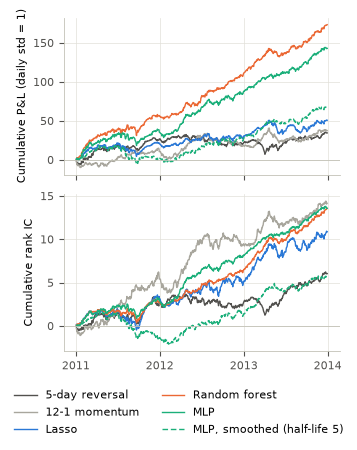

In [49]:
# Figure 2: test period, cumulative P&L (each series divided by its daily std) and cumulative daily rank IC
SERIES = [("baseline_rev_5", "5-day reversal", "#52514e", "-"), ("baseline_mom_12_1", "12-1 momentum", "#a8a69d", "-"),
          ("lasso", "Lasso", "#2a78d6", "-"), ("rf", "Random forest", "#eb6834", "-"),
          ("mlp", "MLP", "#1baf7a", "-"), ("mlp_slow", "MLP, smoothed (half-life 5)", "#1baf7a", (0, (4, 2)))]
with plt.rc_context(SMALL):
    fig, ax = plt.subplots(2, 1, figsize=(3.5, 4.4), sharex=True)
    for name, label, color, style in SERIES:
        pnl = TEST_PNL[name].dropna()
        ic = TEST_IC[name].dropna()
        ax[0].plot(pnl.index, (pnl / pnl.std()).cumsum(), color=color, linestyle=style, label=label)   # days up to t
        ax[1].plot(ic.index, ic.cumsum(), color=color, linestyle=style)                                 # days up to t
    ax[0].set_ylabel("Cumulative P&L (daily std = 1)")
    ax[1].set_ylabel("Cumulative rank IC")
    for a in ax:
        a.axhline(0, color="#c3c2b7", linewidth=0.6)
    ax[1].xaxis.set_major_locator(mdates.YearLocator())
    ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    handles, labels = ax[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.0))
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    fig.savefig(FIGURES / "fig_t3_test.pdf", bbox_inches="tight")
    plt.show()

## 10. How many configurations were evaluated

In [50]:
log = pd.DataFrame(EXPERIMENT_LOG)
phase_names = {0: "harness checks (Phase 0)", 2: "development, before the freeze (Phase 2)",
               3: "test evaluation and post-hoc analyses (Phase 3)"}
counts = log.groupby("phase").size().rename(index=phase_names).to_frame("rows")
check_value("total rows in the experiment log", len(log), VERIFY["total_rows"], tol=0.5)
report_checks("Final")
print(f"Total rows in the experiment log: {len(log)}")
development = log[log.phase == 2]
print(f"Of the {len(development)} development rows, controls and diagnostics (never eligible): "
      f"{development.model.str.startswith(('control', 'diagnostic')).sum()}")
print(f"Numbers compared with the recorded values: {CHECKS['n']}, all equal to 4 decimals")
print(f"Run time of this section: {(time.time() - NOTEBOOK_START) / 60:.0f} minutes")
counts

Final: all 587 numbers checked so far match the recorded values to 4 decimals
Total rows in the experiment log: 84
Of the 62 development rows, controls and diagnostics (never eligible): 7
Numbers compared with the recorded values: 587, all equal to 4 decimals
Run time of this section: 270 minutes


,rows
phase,
harness checks (Phase 0),4
"development, before the freeze (Phase 2)",62
test evaluation and post-hoc analyses (Phase 3),18
